
# LUAD vs LUSC Gene Expression Classification — Final Model Pipeline


## 1. Imports and Environment Setup

In [1]:

import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score,
    confusion_matrix, classification_report
)

import lightgbm as lgb
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

try:
    import tensorflow as tf
    from tensorflow import keras
    tf.get_logger().setLevel("ERROR")
    HAS_TF = True
except ImportError:
    HAS_TF = False
    print("[info] tensorflow not installed -> the CNN candidate will be skipped. "
          "Install with: pip install tensorflow-cpu")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
if HAS_TF:
    tf.random.set_seed(RANDOM_STATE)

OUTPUT_DIR = "../results/final_pipeline"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Environment ready. CPU cores available:", os.cpu_count())
print("TensorFlow available:", HAS_TF)


Environment ready. CPU cores available: 8
TensorFlow available: True



## 2. Configuration 

In [4]:

PATHS = {"LUAD": "../data/LUAD.csv", "LUSC": "../data/LUSC.csv"}

# ======================= THE MAIN SWITCH ======================
QUICK_TEST_MODE = False   # <-- SET TO False FOR YOUR REAL / FINAL RUN
# ================================================================

N_CPU_THREADS = 2   # raise this if your machine has more cores available

if QUICK_TEST_MODE:
    N_COMPARISON_REPEATS = 3
    N_FINAL_REPEATS = 3
    N_TUNING_TRIALS = 5
    N_TUNING_CV_FOLDS = 2
    CNN_EPOCHS = 5
    ADABOOST_N_ESTIMATORS = 20
    RF_N_ESTIMATORS = 100
    print("QUICK_TEST_MODE is ON: using small settings to verify the pipeline runs with zero errors.")
    print("Set QUICK_TEST_MODE = False above for your real, full-fidelity results.")
else:
    N_COMPARISON_REPEATS = 20
    N_FINAL_REPEATS = 30
    N_TUNING_TRIALS = 20
    N_TUNING_CV_FOLDS = 5
    CNN_EPOCHS = 100
    ADABOOST_N_ESTIMATORS = 200
    RF_N_ESTIMATORS = 500
    print("QUICK_TEST_MODE is OFF: running full-fidelity settings. This may take a long time on a single core.")

MAX_BOOST_ROUNDS = 500
EARLY_STOPPING_ROUNDS = 30

print(f"\nConfig: N_COMPARISON_REPEATS={N_COMPARISON_REPEATS}, N_FINAL_REPEATS={N_FINAL_REPEATS}, "
      f"N_TUNING_TRIALS={N_TUNING_TRIALS}")


QUICK_TEST_MODE is OFF: running full-fidelity settings. This may take a long time on a single core.

Config: N_COMPARISON_REPEATS=20, N_FINAL_REPEATS=30, N_TUNING_TRIALS=20



## 3. Data Loading — Primary Tumor Only, All Genes


In [5]:

def load_primary_tumor(path, label):
    expr = pd.read_csv(path, index_col=0).T
    expr.index.name = "sampleID"
    n_before = len(expr)
    expr = expr[expr.index.str.endswith("-01")]
    print(f"  {label}: {n_before} raw samples -> {len(expr)} Primary Tumor samples")
    y = pd.Series(label, index=expr.index)
    return expr.astype(np.float32), y


print("Loading TCGA LUAD and LUSC (Primary Tumor only)...")
X_luad, y_luad = load_primary_tumor(PATHS["LUAD"], "LUAD")
X_lusc, y_lusc = load_primary_tumor(PATHS["LUSC"], "LUSC")

common_genes = X_luad.columns.intersection(X_lusc.columns)
X = pd.concat([X_luad[common_genes], X_lusc[common_genes]], axis=0)
y = pd.concat([y_luad, y_lusc], axis=0)
y_bin = (y == "LUSC").astype(int).values
X_vals = X.values

print(f"\nTotal: {len(X)} samples ({y.value_counts().to_dict()}), {X.shape[1]} genes (ALL genes used)")


Loading TCGA LUAD and LUSC (Primary Tumor only)...
  LUAD: 576 raw samples -> 515 Primary Tumor samples
  LUSC: 553 raw samples -> 502 Primary Tumor samples

Total: 1017 samples ({'LUAD': 515, 'LUSC': 502}), 20530 genes (ALL genes used)



## 4. Exploratory Data Analysis (EDA)


=== Class balance ===
LUAD    515
LUSC    502
Name: count, dtype: int64
Missing values in expression matrix: 0


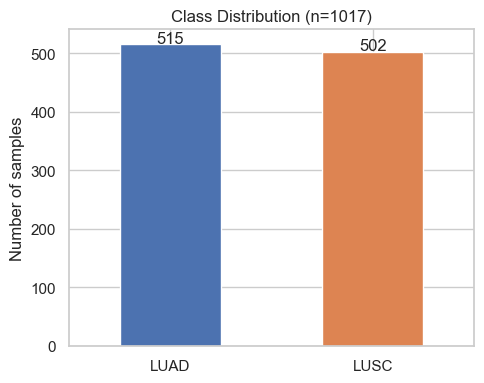

In [6]:

print("=== Class balance ===")
print(y.value_counts())
print(f"Missing values in expression matrix: {X.isna().sum().sum()}")

fig, ax = plt.subplots(figsize=(5, 4))
y.value_counts().reindex(["LUAD", "LUSC"]).plot(
    kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title(f"Class Distribution (n={len(y)})")
ax.set_ylabel("Number of samples")
for i, v in enumerate(y.value_counts().reindex(["LUAD", "LUSC"]).values):
    ax.text(i, v + 3, str(v), ha="center")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/eda_class_balance.png", dpi=150)
plt.show()


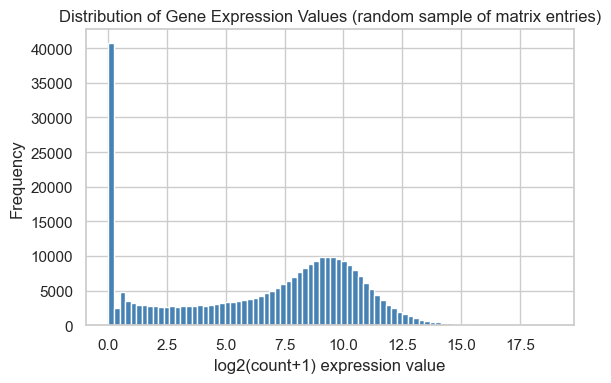

Zero-variance genes: 272 / 20530


In [7]:

rng = np.random.RandomState(RANDOM_STATE)
flat_vals = X_vals.flatten()
sample_idx = rng.choice(len(flat_vals), size=min(300_000, len(flat_vals)), replace=False)
sampled_vals = flat_vals[sample_idx]

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(sampled_vals, bins=80, color="steelblue", edgecolor="white")
ax.set_title("Distribution of Gene Expression Values (random sample of matrix entries)")
ax.set_xlabel("log2(count+1) expression value")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/eda_value_distribution.png", dpi=150)
plt.show()

gene_var = X.var(axis=0)
print(f"Zero-variance genes: {(gene_var == 0).sum()} / {len(gene_var)}")


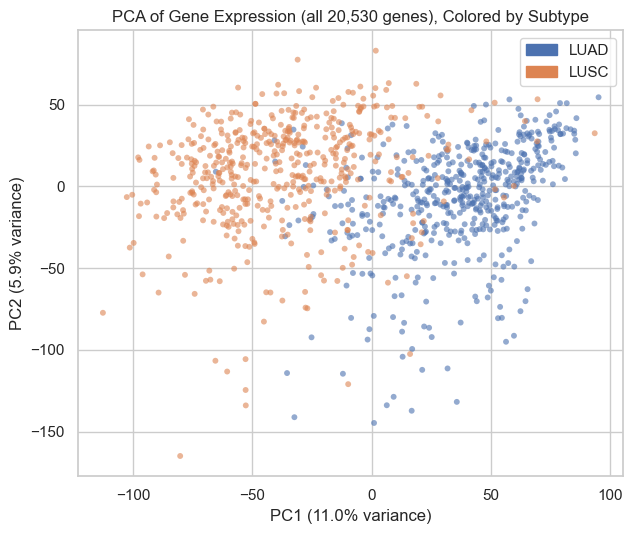

In [8]:

X_scaled_eda = StandardScaler().fit_transform(X_vals)
pca_eda = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_eda.fit_transform(X_scaled_eda)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = y.map({"LUAD": "#4C72B0", "LUSC": "#DD8452"})
ax.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.6, s=18, edgecolor="none")
ax.set_xlabel(f"PC1 ({pca_eda.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca_eda.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("PCA of Gene Expression (all 20,530 genes), Colored by Subtype")
ax.legend(handles=[mpatches.Patch(color="#4C72B0", label="LUAD"),
                    mpatches.Patch(color="#DD8452", label="LUSC")])
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/eda_pca_scatter.png", dpi=150)
plt.show()


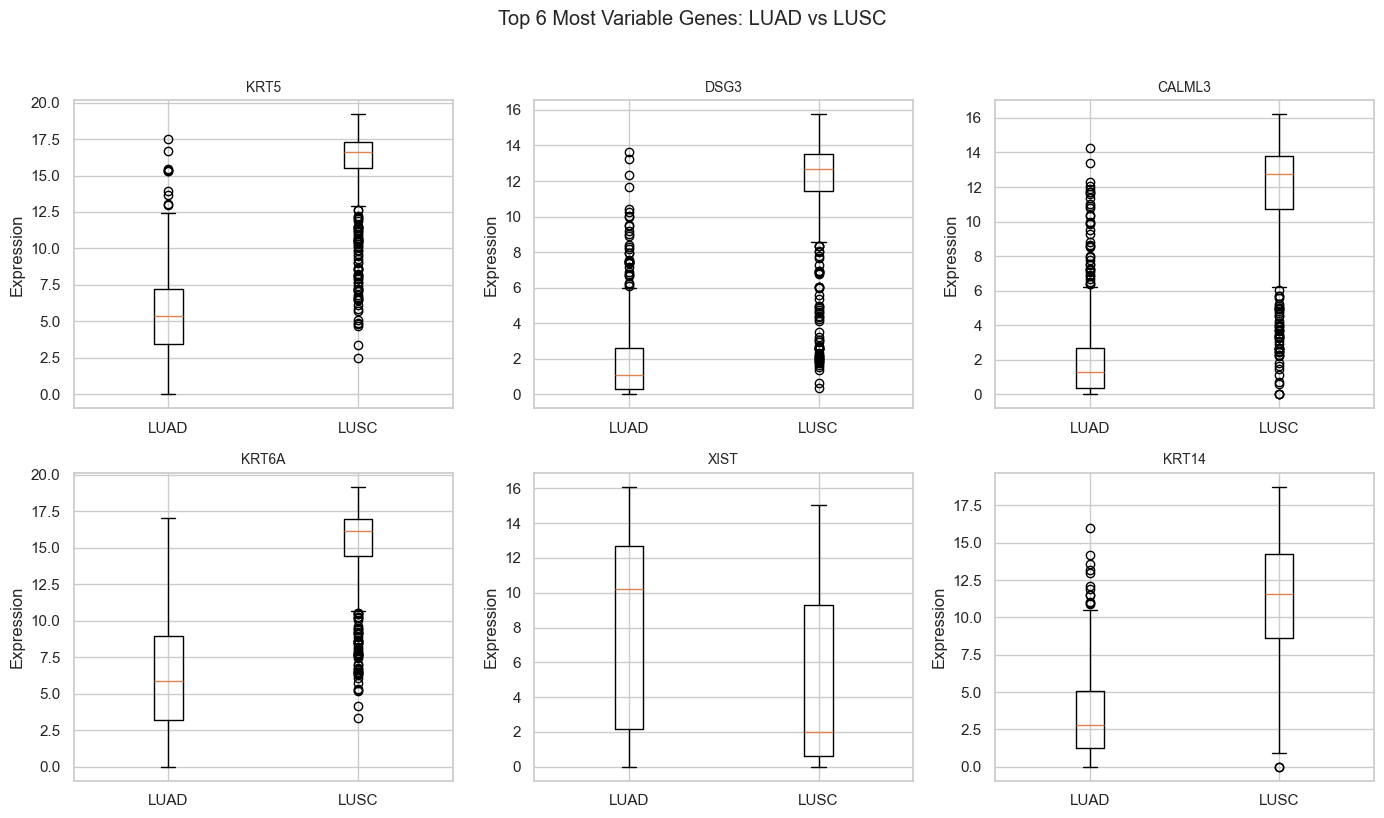

In [9]:

top_var_idx = np.argsort(gene_var.values)[::-1][:6]
top_var_genes = X.columns[top_var_idx]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, gene in zip(axes.flatten(), top_var_genes):
    data_luad = X.loc[y.values == "LUAD", gene]
    data_lusc = X.loc[y.values == "LUSC", gene]
    ax.boxplot([data_luad, data_lusc], tick_labels=["LUAD", "LUSC"])
    ax.set_title(gene, fontsize=10)
    ax.set_ylabel("Expression")
plt.suptitle("Top 6 Most Variable Genes: LUAD vs LUSC", y=1.02)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/eda_top_genes_boxplot.png", dpi=150)
plt.show()



## 5. Model Comparison — Across Multiple Random Splits



In [10]:

def get_fresh_models():
    '''Returns a fresh dict of un-fitted model instances (fixed, reasonable
    hyperparameters -- not yet tuned; tuning happens in Section 6 for the winner only).'''
    return {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "LinearSVM": LinearSVC(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=RF_N_ESTIMATORS,
                                                class_weight="balanced_subsample",
                                                random_state=RANDOM_STATE, n_jobs=-1),
        "AdaBoost": AdaBoostClassifier(n_estimators=ADABOOST_N_ESTIMATORS, random_state=RANDOM_STATE),
    }


def fit_predict_sklearn(model, Xtr, ytr, Xte):
    model.fit(Xtr, ytr)
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(Xte)[:, 1]
    else:
        scores = model.decision_function(Xte)
        proba = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)
    pred = (proba >= 0.5).astype(int)
    return proba, pred


def fit_predict_xgb(Xtr, ytr, Xva, yva, Xte):
    m = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.08,
                           tree_method="hist", max_bin=63, eval_metric="logloss",
                           random_state=RANDOM_STATE, n_jobs=N_CPU_THREADS)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    proba = m.predict_proba(Xte)[:, 1]
    return proba, (proba >= 0.5).astype(int)


def fit_predict_lgb(Xtr, ytr, Xva, yva, Xte, params=None):
    train_ds = lgb.Dataset(Xtr, label=ytr, params={"max_bin": 63, "feature_pre_filter": False})
    val_ds = lgb.Dataset(Xva, label=yva, reference=train_ds)
    p = params or {"objective": "binary", "metric": "auc", "verbose": -1,
                    "num_threads": N_CPU_THREADS, "max_bin": 63,
                    "num_leaves": 31, "learning_rate": 0.08, "max_depth": 4}
    bst = lgb.train(p, train_ds, num_boost_round=300, valid_sets=[val_ds],
                     callbacks=[lgb.early_stopping(20, verbose=False)])
    proba = bst.predict(Xte)
    return proba, (proba >= 0.5).astype(int)


def build_cnn(n_features):
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features, 1)),
        keras.layers.Conv1D(16, kernel_size=5, activation="relu"),
        keras.layers.Flatten(),
        keras.layers.Dropout(0.4),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="binary_crossentropy", metrics=["AUC"])
    return model


def fit_predict_cnn(Xtr, ytr, Xva, yva, Xte):
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xva_s, Xte_s = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    model = build_cnn(Xtr_s.shape[1])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    model.fit(Xtr_s[..., None], ytr, validation_data=(Xva_s[..., None], yva),
              epochs=CNN_EPOCHS, batch_size=16, callbacks=[es], verbose=0)
    proba = model.predict(Xte_s[..., None], verbose=0).flatten()
    return proba, (proba >= 0.5).astype(int)


print("Model-building functions defined.")


Model-building functions defined.


In [11]:
import os
import pickle

comparison_checkpoint_path = os.path.join(OUTPUT_DIR, "checkpoint_model_comparison.pkl")
SKIP_COMPARISON_LOOP = os.path.exists(comparison_checkpoint_path)

if SKIP_COMPARISON_LOOP:
    print("Checkpoint found. Loading saved results instead of re-running the 6-hour loop...")
    with open(comparison_checkpoint_path, "rb") as f:
        _ckpt = pickle.load(f)
    comparison_rows = _ckpt["comparison_rows"]
    comparison_long_df = _ckpt["comparison_long_df"]
    print(f"Loaded {len(comparison_rows)} rows successfully.")
else:
    print("No checkpoint found. The 6-hour loop below will run normally.")

Checkpoint found. Loading saved results instead of re-running the 6-hour loop...
Loaded 140 rows successfully.


In [12]:
if not SKIP_COMPARISON_LOOP:
        
    comparison_rows = []
    t0 = time.time()

    for seed in range(N_COMPARISON_REPEATS):
        Xtr, Xtemp, ytr, ytemp = train_test_split(X_vals, y_bin, test_size=0.2,
                                                    random_state=seed, stratify=y_bin)
        Xva, Xte, yva, yte = train_test_split(Xtemp, ytemp, test_size=0.5,
                                                random_state=seed, stratify=ytemp)

        sk_models = get_fresh_models()
        for name, model in sk_models.items():
            proba, pred = fit_predict_sklearn(model, Xtr, ytr, Xte)
            comparison_rows.append({"seed": seed, "Model": name,
                                    "AUC": roc_auc_score(yte, proba),
                                    "Accuracy": accuracy_score(yte, pred),
                                    "F1": f1_score(yte, pred)})

        proba, pred = fit_predict_xgb(Xtr, ytr, Xva, yva, Xte)
        comparison_rows.append({"seed": seed, "Model": "XGBoost",
                                "AUC": roc_auc_score(yte, proba),
                                "Accuracy": accuracy_score(yte, pred),
                                "F1": f1_score(yte, pred)})

        proba, pred = fit_predict_lgb(Xtr, ytr, Xva, yva, Xte)
        comparison_rows.append({"seed": seed, "Model": "LightGBM",
                                "AUC": roc_auc_score(yte, proba),
                                "Accuracy": accuracy_score(yte, pred),
                                "F1": f1_score(yte, pred)})

        if HAS_TF:
            proba, pred = fit_predict_cnn(Xtr, ytr, Xva, yva, Xte)
            comparison_rows.append({"seed": seed, "Model": "CNN (Conv1D)",
                                    "AUC": roc_auc_score(yte, proba),
                                    "Accuracy": accuracy_score(yte, pred),
                                    "F1": f1_score(yte, pred)})

        print(f"  repeat {seed+1}/{N_COMPARISON_REPEATS} done ({time.time()-t0:.1f}s elapsed total)")

    comparison_long_df = pd.DataFrame(comparison_rows)
    print(f"\nAll {N_COMPARISON_REPEATS} comparison repeats completed in {time.time()-t0:.1f}s")


In [ ]:
import pickle, os

comparison_checkpoint_path = os.path.join(OUTPUT_DIR, "checkpoint_model_comparison.pkl")

with open(comparison_checkpoint_path, "wb") as f:
    pickle.dump({
        "comparison_rows": comparison_rows,
        "comparison_long_df": comparison_long_df,
    }, f)

print(f"[checkpoint] সফলভাবে save হয়েছে: {comparison_checkpoint_path}")
print(f"[checkpoint] File size: {os.path.getsize(comparison_checkpoint_path) / 1024:.1f} KB")
print(f"[checkpoint] মোট {len(comparison_rows)} টা row save হয়েছে ({N_COMPARISON_REPEATS} repeat x 7 model)।")

[checkpoint] সফলভাবে save হয়েছে: results_final_pipeline\checkpoint_model_comparison.pkl
[checkpoint] File size: 11.8 KB
[checkpoint] মোট 140 টা row save হয়েছে (20 repeat x 7 model)।


=== MODEL COMPARISON -- averaged over 20 independent splits ===
             Model  Mean_Accuracy  Std_Accuracy  Mean_AUC  Std_AUC  Mean_F1
LogisticRegression       0.959314      0.017502  0.990598 0.009065 0.958689
          AdaBoost       0.958824      0.016405  0.992386 0.009004 0.958361
         LinearSVM       0.957353      0.019420  0.990943 0.009041 0.956738
           XGBoost       0.957353      0.020925  0.992116 0.008423 0.956463
      CNN (Conv1D)       0.953922      0.020639  0.987637 0.010083 0.952918
      RandomForest       0.951471      0.016673  0.986445 0.008053 0.950022
          LightGBM       0.944608      0.026665  0.986176 0.011063 0.943743

>>> WINNING MODEL (highest mean accuracy): LogisticRegression
>>> Mean Accuracy: 95.93% +- 1.75%
>>> Mean AUC:      0.9906 +- 0.0091


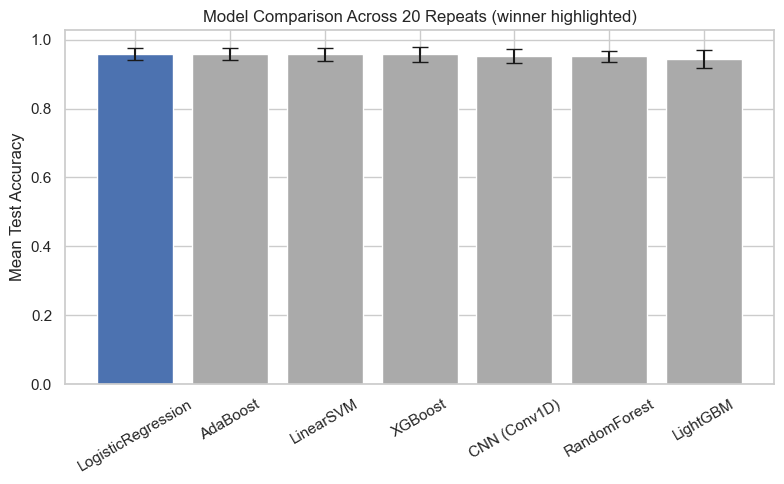

In [13]:

summary_df = (comparison_long_df.groupby("Model")
              .agg(Mean_Accuracy=("Accuracy", "mean"), Std_Accuracy=("Accuracy", "std"),
                   Mean_AUC=("AUC", "mean"), Std_AUC=("AUC", "std"),
                   Mean_F1=("F1", "mean"))
              .fillna(0)
              .sort_values("Mean_Accuracy", ascending=False)
              .reset_index())

print(f"=== MODEL COMPARISON -- averaged over {N_COMPARISON_REPEATS} independent splits ===")
print(summary_df.to_string(index=False))

WINNING_MODEL = summary_df.iloc[0]["Model"]
print(f"\n>>> WINNING MODEL (highest mean accuracy): {WINNING_MODEL}")
print(f">>> Mean Accuracy: {summary_df.iloc[0]['Mean_Accuracy']*100:.2f}% "
      f"+- {summary_df.iloc[0]['Std_Accuracy']*100:.2f}%")
print(f">>> Mean AUC:      {summary_df.iloc[0]['Mean_AUC']:.4f} +- {summary_df.iloc[0]['Std_AUC']:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(summary_df["Model"], summary_df["Mean_Accuracy"], yerr=summary_df["Std_Accuracy"],
       capsize=6, color=["#4C72B0" if m == WINNING_MODEL else "#AAAAAA" for m in summary_df["Model"]])
ax.set_ylabel("Mean Test Accuracy")
ax.set_title(f"Model Comparison Across {N_COMPARISON_REPEATS} Repeats (winner highlighted)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/model_comparison_multirepeat.png", dpi=150)
plt.show()

comparison_long_df.to_csv(f"{OUTPUT_DIR}/model_comparison_raw.csv", index=False)
summary_df.to_csv(f"{OUTPUT_DIR}/model_comparison_summary.csv", index=False)



## 6. Hyperparameter Tuning — Trying to Improve the Winning Model Further


In [14]:

Xtr_tune, Xtemp_tune, ytr_tune, ytemp_tune = train_test_split(
    X_vals, y_bin, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bin)
Xva_tune, Xte_tune, yva_tune, yte_tune = train_test_split(
    Xtemp_tune, ytemp_tune, test_size=0.5, random_state=RANDOM_STATE, stratify=ytemp_tune)

tuned_params = None  # will hold the winning model's tuned hyperparameters, if applicable

t0 = time.time()

if WINNING_MODEL == "LightGBM":
    train_ds = lgb.Dataset(Xtr_tune, label=ytr_tune, params={"max_bin": 63, "feature_pre_filter": False})

    def objective(trial):
        params = {
            "objective": "binary", "metric": "auc", "verbose": -1, "num_threads": N_CPU_THREADS,
            "max_bin": 63,
            "num_leaves": trial.suggest_int("num_leaves", 7, 63),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 7),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 30),
            "feature_fraction": trial.suggest_float("feature_fraction", 0.3, 1.0),
        }
        cv_result = lgb.cv(params, train_ds, num_boost_round=150, nfold=N_TUNING_CV_FOLDS,
                            stratified=True, seed=RANDOM_STATE,
                            callbacks=[lgb.early_stopping(15, verbose=False)])
        return max(cv_result["valid auc-mean"])

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = dict(study.best_params)
    tuned_params.update({"objective": "binary", "metric": "auc", "verbose": -1,
                          "num_threads": N_CPU_THREADS, "max_bin": 63})
    print(f"Best LightGBM params: {tuned_params}")

elif WINNING_MODEL == "XGBoost":
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 400),
            "max_depth": trial.suggest_int("max_depth", 3, 7),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
            "tree_method": "hist", "max_bin": 63, "eval_metric": "logloss",
            "random_state": RANDOM_STATE, "n_jobs": N_CPU_THREADS,
        }
        m = xgb.XGBClassifier(**params)
        m.fit(Xtr_tune, ytr_tune, eval_set=[(Xva_tune, yva_tune)], verbose=False)
        return roc_auc_score(yva_tune, m.predict_proba(Xva_tune)[:, 1])

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = dict(study.best_params)
    tuned_params.update({"tree_method": "hist", "max_bin": 63, "eval_metric": "logloss",
                          "random_state": RANDOM_STATE, "n_jobs": N_CPU_THREADS})
    print(f"Best XGBoost params: {tuned_params}")

elif WINNING_MODEL == "RandomForest":
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 600),
            "max_depth": trial.suggest_int("max_depth", 4, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "max_features": trial.suggest_float("max_features", 0.1, 0.8),
            "class_weight": "balanced_subsample", "random_state": RANDOM_STATE, "n_jobs": -1,
        }
        m = RandomForestClassifier(**params)
        m.fit(Xtr_tune, ytr_tune)
        return roc_auc_score(yva_tune, m.predict_proba(Xva_tune)[:, 1])

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = dict(study.best_params)
    tuned_params.update({"class_weight": "balanced_subsample", "random_state": RANDOM_STATE, "n_jobs": -1})
    print(f"Best RandomForest params: {tuned_params}")

elif WINNING_MODEL == "AdaBoost":
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 30, 300),
            "learning_rate": trial.suggest_float("learning_rate", 0.1, 1.5, log=True),
            "random_state": RANDOM_STATE,
        }
        m = AdaBoostClassifier(**params)
        m.fit(Xtr_tune, ytr_tune)
        return roc_auc_score(yva_tune, m.predict_proba(Xva_tune)[:, 1])

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = dict(study.best_params)
    tuned_params.update({"random_state": RANDOM_STATE})
    print(f"Best AdaBoost params: {tuned_params}")

elif WINNING_MODEL in ("LogisticRegression", "LinearSVM"):
    def objective(trial):
        C = trial.suggest_float("C", 1e-4, 10.0, log=True)
        if WINNING_MODEL == "LogisticRegression":
            m = LogisticRegression(C=C, max_iter=3000, class_weight="balanced")
            m.fit(Xtr_tune, ytr_tune)
            proba = m.predict_proba(Xva_tune)[:, 1]
        else:
            m = LinearSVC(C=C, class_weight="balanced", max_iter=8000, random_state=RANDOM_STATE)
            m.fit(Xtr_tune, ytr_tune)
            scores = m.decision_function(Xva_tune)
            proba = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)
        return roc_auc_score(yva_tune, proba)

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = {"C": study.best_params["C"]}
    print(f"Best C for {WINNING_MODEL}: {tuned_params}")

else:
    print(f"No tuning routine defined for {WINNING_MODEL} (e.g. CNN) -- reusing its default architecture.")

print(f"\nTuning completed in {time.time()-t0:.1f}s")


Best C for LogisticRegression: {'C': 6.581332043291798}

Tuning completed in 75.2s



## 7. Final Robustness Evaluation — the Winning, Tuned Model Across Many Splits



In [15]:

def train_predict_winning_model(seed):
    Xtr, Xtemp, ytr, ytemp = train_test_split(X_vals, y_bin, test_size=0.2,
                                                random_state=seed, stratify=y_bin)
    Xva, Xte, yva, yte = train_test_split(Xtemp, ytemp, test_size=0.5,
                                            random_state=seed, stratify=ytemp)

    if WINNING_MODEL == "LightGBM":
        proba, pred = fit_predict_lgb(Xtr, ytr, Xva, yva, Xte, params=tuned_params)
    elif WINNING_MODEL == "XGBoost":
        m = xgb.XGBClassifier(**tuned_params)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        proba = m.predict_proba(Xte)[:, 1]
        pred = (proba >= 0.5).astype(int)
    elif WINNING_MODEL == "RandomForest":
        m = RandomForestClassifier(**tuned_params)
        m.fit(Xtr, ytr)
        proba = m.predict_proba(Xte)[:, 1]
        pred = (proba >= 0.5).astype(int)
    elif WINNING_MODEL == "AdaBoost":
        m = AdaBoostClassifier(**tuned_params)
        m.fit(Xtr, ytr)
        proba = m.predict_proba(Xte)[:, 1]
        pred = (proba >= 0.5).astype(int)
    elif WINNING_MODEL == "LogisticRegression":
        m = LogisticRegression(C=tuned_params["C"], max_iter=3000, class_weight="balanced")
        proba, pred = fit_predict_sklearn(m, Xtr, ytr, Xte)
    elif WINNING_MODEL == "LinearSVM":
        m = LinearSVC(C=tuned_params["C"], class_weight="balanced", max_iter=8000, random_state=RANDOM_STATE)
        proba, pred = fit_predict_sklearn(m, Xtr, ytr, Xte)
    elif WINNING_MODEL == "CNN (Conv1D)":
        proba, pred = fit_predict_cnn(Xtr, ytr, Xva, yva, Xte)
    else:
        raise ValueError(f"Unknown winning model: {WINNING_MODEL}")

    return yte, pred, proba


final_aucs, final_accs = [], []
all_y_true, all_y_pred, all_y_proba = [], [], []
t1 = time.time()

for seed in range(N_FINAL_REPEATS):
    yte, pred, proba = train_predict_winning_model(seed)
    auc = roc_auc_score(yte, proba)
    acc = accuracy_score(yte, pred)
    final_aucs.append(auc); final_accs.append(acc)
    all_y_true.append(yte); all_y_pred.append(pred); all_y_proba.append(proba)
    print(f"  repeat {seed+1}/{N_FINAL_REPEATS}: test AUC={auc:.4f}  test accuracy={acc*100:.2f}%  "
          f"({time.time()-t1:.1f}s elapsed total)")

print(f"\nAll {N_FINAL_REPEATS} final repeats completed in {time.time()-t1:.1f}s")
all_y_true = np.concatenate(all_y_true)
all_y_pred = np.concatenate(all_y_pred)
all_y_proba = np.concatenate(all_y_proba)
print(f"Pooled test predictions across all repeats: {len(all_y_true)} samples")


  repeat 1/30: test AUC=0.9973  test accuracy=99.02%  (1.8s elapsed total)
  repeat 2/30: test AUC=0.9985  test accuracy=98.04%  (4.2s elapsed total)
  repeat 3/30: test AUC=0.9900  test accuracy=94.12%  (6.5s elapsed total)
  repeat 4/30: test AUC=0.9873  test accuracy=97.06%  (8.1s elapsed total)
  repeat 5/30: test AUC=0.9885  test accuracy=96.08%  (10.7s elapsed total)
  repeat 6/30: test AUC=0.9865  test accuracy=94.12%  (12.9s elapsed total)
  repeat 7/30: test AUC=0.9781  test accuracy=95.10%  (14.9s elapsed total)
  repeat 8/30: test AUC=0.9935  test accuracy=97.06%  (16.6s elapsed total)
  repeat 9/30: test AUC=0.9977  test accuracy=98.04%  (19.1s elapsed total)
  repeat 10/30: test AUC=0.9938  test accuracy=98.04%  (21.5s elapsed total)
  repeat 11/30: test AUC=0.9915  test accuracy=93.14%  (24.2s elapsed total)
  repeat 12/30: test AUC=0.9869  test accuracy=95.10%  (26.6s elapsed total)
  repeat 13/30: test AUC=0.9931  test accuracy=96.08%  (28.3s elapsed total)
  repeat 14/

## 8. Final Result — Summary

In [16]:

mean_auc, std_auc = np.mean(final_aucs), np.std(final_aucs)
mean_acc, std_acc = np.mean(final_accs), np.std(final_accs)

print("=" * 60)
print(f"FINAL PIPELINE RESULT -- Winning Model: {WINNING_MODEL}")
print("=" * 60)
print(f"Mean Test Accuracy ({N_FINAL_REPEATS} repeats): {mean_acc*100:.2f}% +- {std_acc*100:.2f}%")
print(f"Mean Test AUC      ({N_FINAL_REPEATS} repeats): {mean_auc:.4f} +- {std_auc:.4f}")
print(f"Accuracy Min / Max: {np.min(final_accs)*100:.2f}% / {np.max(final_accs)*100:.2f}%")
print(f"AUC      Min / Max: {np.min(final_aucs):.4f} / {np.max(final_aucs):.4f}")


FINAL PIPELINE RESULT -- Winning Model: LogisticRegression
Mean Test Accuracy (30 repeats): 95.69% +- 1.73%
Mean Test AUC      (30 repeats): 0.9884 +- 0.0080
Accuracy Min / Max: 91.18% / 99.02%
AUC      Min / Max: 0.9631 / 0.9992



## 9. Final Confusion Matrix — Pooled Across All Repeats




Pooled test predictions: 3060 samples across 30 repeats
Pooled Accuracy: 95.69%   (Section 8 mean: 95.69% +- 1.73%)
Pooled AUC:      0.9880   (Section 8 mean: 0.9884 +- 0.0080)

Classification Report (0=LUAD, 1=LUSC), pooled, model=LogisticRegression:
              precision    recall  f1-score   support

        LUAD       0.95      0.96      0.96      1541
        LUSC       0.96      0.95      0.96      1519

    accuracy                           0.96      3060
   macro avg       0.96      0.96      0.96      3060
weighted avg       0.96      0.96      0.96      3060



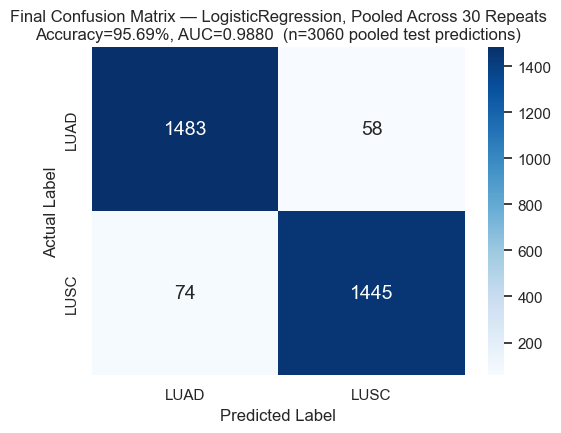

In [17]:

pooled_accuracy = accuracy_score(all_y_true, all_y_pred)
pooled_auc = roc_auc_score(all_y_true, all_y_proba)

print(f"Pooled test predictions: {len(all_y_true)} samples across {N_FINAL_REPEATS} repeats")
print(f"Pooled Accuracy: {pooled_accuracy*100:.2f}%   (Section 8 mean: {mean_acc*100:.2f}% +- {std_acc*100:.2f}%)")
print(f"Pooled AUC:      {pooled_auc:.4f}   (Section 8 mean: {mean_auc:.4f} +- {std_auc:.4f})")
print()
print(f"Classification Report (0=LUAD, 1=LUSC), pooled, model={WINNING_MODEL}:")
print(classification_report(all_y_true, all_y_pred, target_names=["LUAD", "LUSC"]))

cm = confusion_matrix(all_y_true, all_y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["LUAD", "LUSC"], yticklabels=["LUAD", "LUSC"], ax=ax,
            annot_kws={"size": 14})
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_title(f"Final Confusion Matrix — {WINNING_MODEL}, Pooled Across {N_FINAL_REPEATS} Repeats\n"
             f"Accuracy={pooled_accuracy*100:.2f}%, AUC={pooled_auc:.4f}  "
             f"(n={len(all_y_true)} pooled test predictions)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/final_confusion_matrix.png", dpi=150)
plt.show()



## 10. Explainable AI (XAI) — SHAP-Based Biomarker Discovery



In [18]:

# Install SHAP if not already available
try:
    import shap
except ImportError:
    import subprocess, sys
    print("Installing shap ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "--quiet"])
    import shap

print("SHAP version:", shap.__version__)
GENE_NAMES = np.array(X.columns)


SHAP version: 0.51.0


In [19]:
# Train the ACTUAL winning model (from Section 5) for SHAP interpretability --
# NOT a separate substitute model. This ensures the XAI analysis explains
# the exact same model your thesis reports as the final, best-performing one.
Xtr_xai, Xtemp_xai, ytr_xai, ytemp_xai = train_test_split(
    X_vals, y_bin, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bin)
Xva_xai, Xte_xai, yva_xai, yte_xai = train_test_split(
    Xtemp_xai, ytemp_xai, test_size=0.5, random_state=RANDOM_STATE, stratify=ytemp_xai)

print(f"Training the ACTUAL winning model ({WINNING_MODEL}) for SHAP analysis...")

if WINNING_MODEL == "LightGBM":
    train_ds_xai = lgb.Dataset(Xtr_xai, label=ytr_xai, params={"max_bin": 63, "feature_pre_filter": False})
    val_ds_xai = lgb.Dataset(Xva_xai, label=yva_xai, reference=train_ds_xai)
    xai_model = lgb.train(tuned_params, train_ds_xai, num_boost_round=MAX_BOOST_ROUNDS,
                           valid_sets=[val_ds_xai],
                           callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
    xai_proba = xai_model.predict(Xte_xai)

elif WINNING_MODEL == "LogisticRegression":
    xai_model = LogisticRegression(C=tuned_params["C"], max_iter=3000, class_weight="balanced")
    xai_model.fit(Xtr_xai, ytr_xai)
    xai_proba = xai_model.predict_proba(Xte_xai)[:, 1]

elif WINNING_MODEL == "LinearSVM":
    xai_model = LinearSVC(C=tuned_params["C"], class_weight="balanced", max_iter=8000, random_state=RANDOM_STATE)
    xai_model.fit(Xtr_xai, ytr_xai)
    scores = xai_model.decision_function(Xte_xai)
    xai_proba = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)

elif WINNING_MODEL == "XGBoost":
    xai_model = xgb.XGBClassifier(**tuned_params)
    xai_model.fit(Xtr_xai, ytr_xai, eval_set=[(Xva_xai, yva_xai)], verbose=False)
    xai_proba = xai_model.predict_proba(Xte_xai)[:, 1]

elif WINNING_MODEL == "RandomForest":
    xai_model = RandomForestClassifier(**tuned_params)
    xai_model.fit(Xtr_xai, ytr_xai)
    xai_proba = xai_model.predict_proba(Xte_xai)[:, 1]

elif WINNING_MODEL == "AdaBoost":
    xai_model = AdaBoostClassifier(**tuned_params)
    xai_model.fit(Xtr_xai, ytr_xai)
    xai_proba = xai_model.predict_proba(Xte_xai)[:, 1]

else:
    raise ValueError(f"No SHAP routine defined for {WINNING_MODEL} (e.g. CNN) -- "
                      f"SHAP for neural networks needs a different explainer (DeepExplainer); "
                      f"ask for that addition separately if CNN wins for you.")

# NOTE: We deliberately do NOT print this single-split's AUC/accuracy here.
# A single 102-sample split's accuracy naturally fluctuates (as demonstrated
# earlier) and printing it invites exactly the confusion we just walked through.
# The model object above exists ONLY to feed SHAP -- your thesis's one and only
# official accuracy number remains Section 5's robust, multi-repeat result:
print(f"\n{WINNING_MODEL} trained successfully for SHAP analysis.")
print(f"Reminder -- your official, reportable accuracy for {WINNING_MODEL} is the "
      f"Section 5 robust estimate:")
print(f"  Mean Accuracy = "
      f"{summary_df.loc[summary_df['Model']==WINNING_MODEL,'Mean_Accuracy'].values[0]*100:.2f}% "
      f"+- {summary_df.loc[summary_df['Model']==WINNING_MODEL,'Std_Accuracy'].values[0]*100:.2f}% "
      f"(averaged over {N_COMPARISON_REPEATS} independent splits).")

Training the ACTUAL winning model (LogisticRegression) for SHAP analysis...

LogisticRegression trained successfully for SHAP analysis.
Reminder -- your official, reportable accuracy for LogisticRegression is the Section 5 robust estimate:
  Mean Accuracy = 95.93% +- 1.75% (averaged over 20 independent splits).


In [20]:
# Choose the correct SHAP explainer type based on which model actually won.
# TreeExplainer = exact & fast for tree-based models.
# LinearExplainer = exact & fast for linear models (LogisticRegression, LinearSVM's decision function).
# Explainer (generic, sampling-based) = fallback for anything else (e.g. AdaBoost).
if WINNING_MODEL in ("LightGBM", "XGBoost", "RandomForest"):
    explainer = shap.TreeExplainer(xai_model)
    shap_values = explainer.shap_values(Xte_xai)
    if isinstance(shap_values, list):          # some SHAP/library version combos return a list
        shap_values = shap_values[1]           # index 1 = positive class = LUSC

elif WINNING_MODEL == "LogisticRegression":
    explainer = shap.LinearExplainer(xai_model, Xtr_xai)
    shap_values = explainer.shap_values(Xte_xai)

elif WINNING_MODEL in ("LinearSVM", "AdaBoost"):
    background = shap.sample(Xtr_xai, 50, random_state=RANDOM_STATE)
    if WINNING_MODEL == "LinearSVM":
        predict_fn = lambda d: xai_model.decision_function(d)
    else:
        predict_fn = lambda d: xai_model.predict_proba(d)[:, 1]
    explainer = shap.Explainer(predict_fn, background)
    shap_values = explainer(Xte_xai).values

else:
    raise ValueError(f"No SHAP routine defined for {WINNING_MODEL}.")

print(f"SHAP values computed for {WINNING_MODEL}: {Xte_xai.shape[0]} test samples, "
      f"{Xte_xai.shape[1]} genes.")
print(f"shap_values shape: {np.array(shap_values).shape}")

SHAP values computed for LogisticRegression: 102 test samples, 20530 genes.
shap_values shape: (102, 20530)


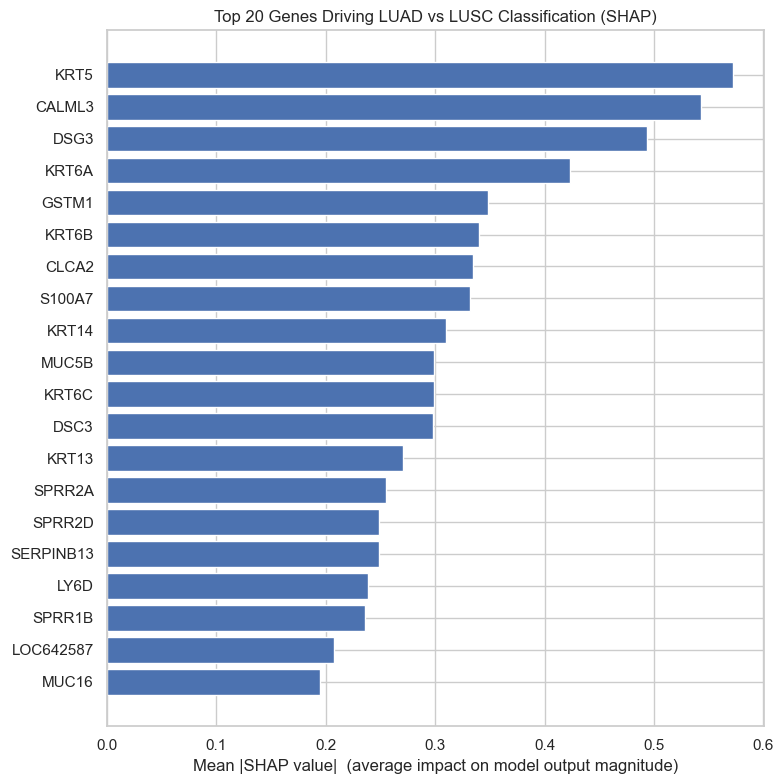


Top 20 genes by SHAP importance:
     gene  mean_abs_shap
     KRT5       0.572500
   CALML3       0.542915
     DSG3       0.493923
    KRT6A       0.423051
    GSTM1       0.348262
    KRT6B       0.340133
    CLCA2       0.334271
   S100A7       0.331995
    KRT14       0.310268
    MUC5B       0.299129
    KRT6C       0.298721
     DSC3       0.298440
    KRT13       0.270397
   SPRR2A       0.254610
   SPRR2D       0.248988
SERPINB13       0.248385
     LY6D       0.238581
   SPRR1B       0.235646
LOC642587       0.207805
    MUC16       0.194249


In [21]:

# SHAP summary plot -- top 20 genes by overall importance (mean |SHAP value|)
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_n = 20
top_idx = np.argsort(mean_abs_shap)[::-1][:top_n]
top_genes = GENE_NAMES[top_idx]
top_importance = mean_abs_shap[top_idx]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(range(top_n), top_importance[::-1], color="#4C72B0")
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_genes[::-1])
ax.set_xlabel("Mean |SHAP value|  (average impact on model output magnitude)")
ax.set_title(f"Top {top_n} Genes Driving LUAD vs LUSC Classification (SHAP)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_top_genes_bar.png", dpi=150)
plt.show()

shap_importance_df = pd.DataFrame({"gene": GENE_NAMES, "mean_abs_shap": mean_abs_shap}) \
    .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_importance_df.to_csv(f"{OUTPUT_DIR}/shap_gene_importance_full.csv", index=False)
print(f"\nTop {top_n} genes by SHAP importance:")
print(shap_importance_df.head(top_n).to_string(index=False))


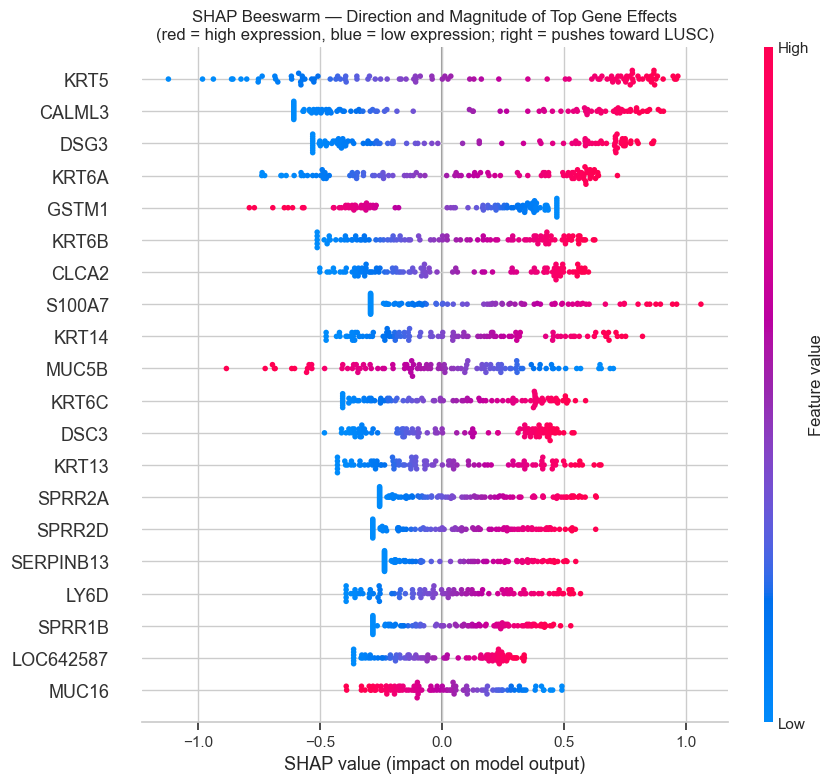

In [22]:

# Beeswarm plot -- shows not just importance but the DIRECTION of each gene's effect
# (does high expression push the prediction toward LUAD or toward LUSC?)
shap.summary_plot(shap_values[:, top_idx], Xte_xai[:, top_idx],
                   feature_names=list(top_genes), show=False, max_display=top_n)
fig = plt.gcf()
fig.set_size_inches(9, 8)
plt.title("SHAP Beeswarm — Direction and Magnitude of Top Gene Effects\n"
          "(red = high expression, blue = low expression; right = pushes toward LUSC)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_beeswarm.png", dpi=150)
plt.show()



### Cross-checking discovered genes against known LUAD/LUSC pathology markers


In [23]:

# Well-established LUAD and LUSC marker genes from the pathology / oncology literature
# (used clinically for immunohistochemistry-based subtype diagnosis)
KNOWN_LUAD_MARKERS = ["NAPSA", "NKX2-1", "TTF1", "SFTPC", "SFTPB", "MUC5B", "NAPSA1"]
KNOWN_LUSC_MARKERS = ["TP63", "KRT5", "KRT6A", "KRT6B", "SOX2", "DSG3", "TP73L"]
KNOWN_MARKERS = set(KNOWN_LUAD_MARKERS) | set(KNOWN_LUSC_MARKERS)

# SHAP gene names in this TCGA/Xena dataset are typically formatted like "GENE|ENTREZID"
# or plain "GENE" -- handle both by matching on the part before any "|"
top_gene_symbols = [str(g).split("|")[0].upper() for g in top_genes]

overlap = [g for g in top_gene_symbols if g in KNOWN_MARKERS]

print(f"Known LUAD markers checked: {KNOWN_LUAD_MARKERS}")
print(f"Known LUSC markers checked: {KNOWN_LUSC_MARKERS}")
print(f"\nOf the top {top_n} SHAP-ranked genes, {len(overlap)} match a known clinical marker:")
for g in overlap:
    print(f"  - {g}")

if len(overlap) == 0:
    print("\n[No overlap found among the exact top-N list above -- consider checking a larger")
    print(" top-K (e.g. top 50-100 genes) using shap_importance_df, since biologically relevant")
    print(" genes sometimes rank just outside the very top slots but are still highly informative.]")


Known LUAD markers checked: ['NAPSA', 'NKX2-1', 'TTF1', 'SFTPC', 'SFTPB', 'MUC5B', 'NAPSA1']
Known LUSC markers checked: ['TP63', 'KRT5', 'KRT6A', 'KRT6B', 'SOX2', 'DSG3', 'TP73L']

Of the top 20 SHAP-ranked genes, 5 match a known clinical marker:
  - KRT5
  - DSG3
  - KRT6A
  - KRT6B
  - MUC5B


In [24]:

# Wider check: how far down the ranked list do we need to go to find each known marker?
print("Rank position of each known marker gene in the full SHAP importance ranking:\n")
all_gene_symbols = pd.Series([str(g).split("|")[0].upper() for g in GENE_NAMES])
ranked_symbols = all_gene_symbols.iloc[np.argsort(mean_abs_shap)[::-1]].reset_index(drop=True)

for marker in KNOWN_LUAD_MARKERS + KNOWN_LUSC_MARKERS:
    matches = ranked_symbols[ranked_symbols == marker]
    if len(matches) > 0:
        rank = matches.index[0] + 1
        print(f"  {marker:<10} -> rank #{rank} out of {len(ranked_symbols)} genes "
              f"(top {rank/len(ranked_symbols)*100:.2f}%)")
    else:
        print(f"  {marker:<10} -> not found in this dataset's gene list")


Rank position of each known marker gene in the full SHAP importance ranking:

  NAPSA      -> rank #806 out of 20530 genes (top 3.93%)
  NKX2-1     -> rank #4430 out of 20530 genes (top 21.58%)
  TTF1       -> rank #13054 out of 20530 genes (top 63.58%)
  SFTPC      -> rank #2326 out of 20530 genes (top 11.33%)
  SFTPB      -> rank #7569 out of 20530 genes (top 36.87%)
  MUC5B      -> rank #10 out of 20530 genes (top 0.05%)
  NAPSA1     -> not found in this dataset's gene list
  TP63       -> rank #52 out of 20530 genes (top 0.25%)
  KRT5       -> rank #1 out of 20530 genes (top 0.00%)
  KRT6A      -> rank #4 out of 20530 genes (top 0.02%)
  KRT6B      -> rank #6 out of 20530 genes (top 0.03%)
  SOX2       -> rank #2875 out of 20530 genes (top 14.00%)
  DSG3       -> rank #3 out of 20530 genes (top 0.01%)
  TP73L      -> not found in this dataset's gene list



### 11.1 Survival Analysis — Do the Top Classification Genes Also Predict Prognosis?




In [25]:

try:
    from lifelines import KaplanMeierFitter
    from lifelines.statistics import logrank_test
except ImportError:
    import subprocess, sys
    print("Installing lifelines ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lifelines", "--quiet"])
    from lifelines import KaplanMeierFitter
    from lifelines.statistics import logrank_test

CLINICAL_PATHS = {
    "LUAD": "../data/TCGA_LUAD_sampleMap_LUAD_clinicalMatrix.xlsx",
    "LUSC": "../data/TCGA_LUSC_sampleMap_LUSC_clinicalMatrix.xlsx",
}

clin_luad = pd.read_excel(CLINICAL_PATHS["LUAD"]).set_index("sampleID")
clin_lusc = pd.read_excel(CLINICAL_PATHS["LUSC"]).set_index("sampleID")
clin_all = pd.concat([clin_luad, clin_lusc])

# Overall survival time (days) and event indicator (1 = death observed, 0 = censored)
# NOTE: TCGA clinical files sometimes contain non-numeric placeholder strings
# (e.g. "[Discrepancy]") in these columns instead of a clean blank/NaN --
# pd.to_numeric(..., errors="coerce") converts those to NaN safely (verified fix).
clin_all["days_to_death"] = pd.to_numeric(clin_all["days_to_death"], errors="coerce")
clin_all["days_to_last_followup"] = pd.to_numeric(clin_all["days_to_last_followup"], errors="coerce")
clin_all["OS_DAYS"] = np.where(clin_all["vital_status"] == "DECEASED",
                                clin_all["days_to_death"], clin_all["days_to_last_followup"])
clin_all["OS_EVENT"] = (clin_all["vital_status"] == "DECEASED").astype(int)
clin_surv = clin_all.dropna(subset=["OS_DAYS"])
clin_surv = clin_surv[clin_surv.index.isin(X.index)]

print(f"Samples with usable survival data (matched to expression data): {len(clin_surv)} / {len(X)}")


Samples with usable survival data (matched to expression data): 1001 / 1017


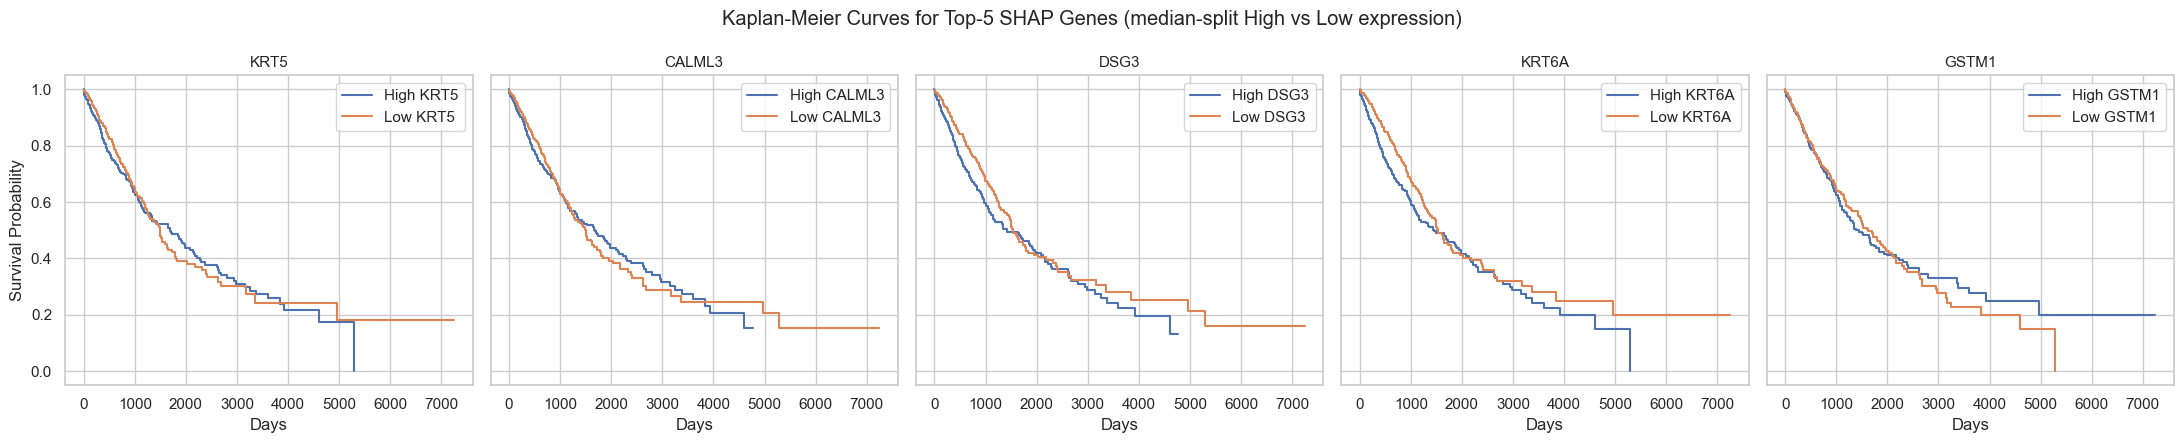


Log-rank test results (p < 0.05 suggests the gene also stratifies survival):
  gene  logrank_p_value  n_high  n_low
 KRT6A         0.015708     501    500
  DSG3         0.029189     501    500
  KRT5         0.637171     501    500
CALML3         0.809596     501    500
 GSTM1         0.963004     501    500

>>> 2 of the top-5 classification-driving genes also significantly stratify overall survival (log-rank p < 0.05).
>>> A gene that does both (classifies AND predicts prognosis) is a stronger, dual-purpose
>>> biomarker finding than classification importance alone -- report these genes explicitly.


In [26]:

# For each of the top-5 SHAP genes, split patients into High vs Low expression
# (median split) and compare survival curves with a log-rank test.

# Safety check: if Section 10 wasn't run first in this kernel session, "top_genes"
# won't exist yet -- recover it from the CSV that Section 10 already saved to disk.
if "top_genes" not in globals():
    _shap_csv_path = os.path.join(OUTPUT_DIR, "shap_gene_importance_full.csv")
    if os.path.exists(_shap_csv_path):
        _shap_importance_df = pd.read_csv(_shap_csv_path)
        top_genes = _shap_importance_df["gene"].values[:20]
        print(f"[info] 'top_genes' recovered from saved file: {_shap_csv_path}")
    else:
        raise RuntimeError(
            "\n\n[SETUP REQUIRED]\n"
            "'top_genes' is not defined, and no saved SHAP results were found at:\n"
            f"    {_shap_csv_path}\n\n"
            "This means Section 10 (Explainable AI / SHAP Analysis) has not been run yet\n"
            "in this notebook session. Please scroll up to Section 10, run every cell in\n"
            "it from top to bottom, and then re-run this cell."
        )

top5_genes_for_survival = list(top_genes[:5])

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)

survival_results = []
for ax, gene in zip(axes, top5_genes_for_survival):
    gene_expr = X.loc[clin_surv.index, gene]
    median_expr = gene_expr.median()
    high_mask = gene_expr >= median_expr
    low_mask = ~high_mask

    kmf_high, kmf_low = KaplanMeierFitter(), KaplanMeierFitter()
    kmf_high.fit(clin_surv.loc[high_mask, "OS_DAYS"], clin_surv.loc[high_mask, "OS_EVENT"],
                 label=f"High {gene}")
    kmf_low.fit(clin_surv.loc[low_mask, "OS_DAYS"], clin_surv.loc[low_mask, "OS_EVENT"],
                label=f"Low {gene}")

    kmf_high.plot_survival_function(ax=ax, ci_show=False)
    kmf_low.plot_survival_function(ax=ax, ci_show=False)
    ax.set_title(gene, fontsize=11)
    ax.set_xlabel("Days")

    result = logrank_test(clin_surv.loc[high_mask, "OS_DAYS"], clin_surv.loc[low_mask, "OS_DAYS"],
                           clin_surv.loc[high_mask, "OS_EVENT"], clin_surv.loc[low_mask, "OS_EVENT"])
    survival_results.append({"gene": gene, "logrank_p_value": result.p_value,
                              "n_high": int(high_mask.sum()), "n_low": int(low_mask.sum())})

axes[0].set_ylabel("Survival Probability")
plt.suptitle("Kaplan-Meier Curves for Top-5 SHAP Genes (median-split High vs Low expression)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_genes_survival_km.png", dpi=150)
plt.show()

survival_df = pd.DataFrame(survival_results).sort_values("logrank_p_value")
print("\nLog-rank test results (p < 0.05 suggests the gene also stratifies survival):")
print(survival_df.to_string(index=False))
survival_df.to_csv(f"{OUTPUT_DIR}/shap_genes_survival_logrank.csv", index=False)

n_significant = (survival_df["logrank_p_value"] < 0.05).sum()
print(f"\n>>> {n_significant} of the top-5 classification-driving genes also significantly "
      f"stratify overall survival (log-rank p < 0.05).")
print(">>> A gene that does both (classifies AND predicts prognosis) is a stronger, dual-purpose")
print(">>> biomarker finding than classification importance alone -- report these genes explicitly.")



### 11.2 Pathway / Gene Ontology (GO) Enrichment of Top SHAP Genes


Top 15 enriched pathways/terms (by adjusted p-value):
                  Gene_set                                                       Term  Adjusted P-value                                                            Genes
GO_Biological_Process_2023                         Epidermis Development (GO:0008544)      7.380214e-09 SPRR2E;SPRR3;CALML5;KRT14;KRT5;SPRR1A;PTHLH;SPRR1B;S100A7;SPRR2D
GO_Biological_Process_2023            Intermediate Filament Organization (GO:0045109)      4.427296e-07                    KRT17;KRT16;KRT14;KRT13;PKP1;KRT5;KRT6B;KRT6A
GO_Biological_Process_2023                              Skin Development (GO:0043588)      7.944220e-06                       SPRR3;KRT16;DACT2;SPRR1A;IVL;SPRR1B;S100A7
GO_Biological_Process_2023                  Keratinocyte Differentiation (GO:0030216)      7.944220e-06                             SPRR3;KRT16;SPRR1A;IVL;SPRR1B;S100A7
GO_Biological_Process_2023                Epidermal Cell Differentiation (GO:0009913)      2.981334e-

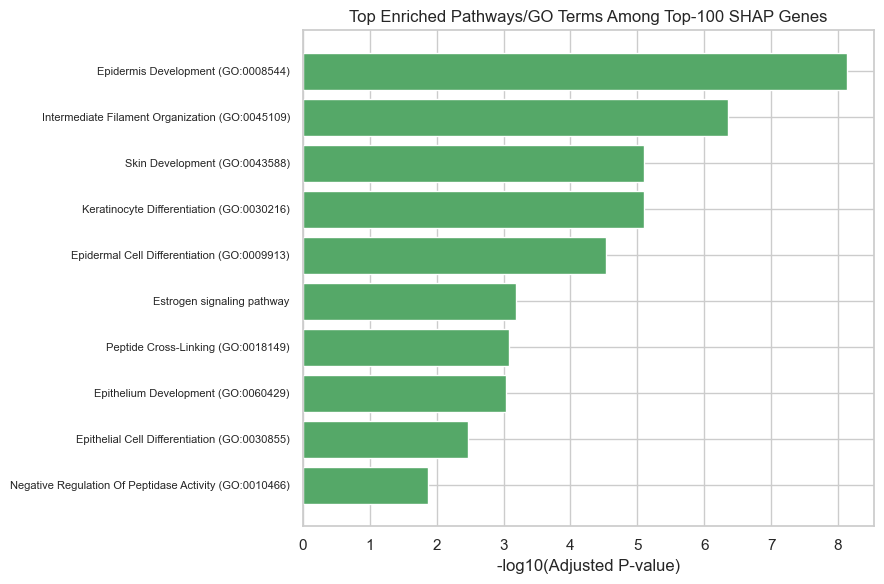

In [27]:

try:
    import gseapy as gp
except ImportError:
    import subprocess, sys
    print("Installing gseapy ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gseapy", "--quiet"])
    import gseapy as gp

# Safety check: recover SHAP importance ranking if Section 10 wasn't run in this session.
if "mean_abs_shap" not in globals() or "GENE_NAMES" not in globals():
    _shap_csv_path = os.path.join(OUTPUT_DIR, "shap_gene_importance_full.csv")
    if os.path.exists(_shap_csv_path):
        _shap_importance_df = pd.read_csv(_shap_csv_path)
        GENE_NAMES = _shap_importance_df["gene"].values
        mean_abs_shap = _shap_importance_df["mean_abs_shap"].values
        print(f"[info] SHAP gene ranking recovered from saved file: {_shap_csv_path}")
    else:
        raise RuntimeError(
            "\n\n[SETUP REQUIRED]\n"
            "SHAP results are not defined, and no saved file was found at:\n"
            f"    {_shap_csv_path}\n\n"
            "Please run Section 10 (Explainable AI / SHAP Analysis) first, then re-run this cell."
        )

# Use a wider gene list (top 100) for enrichment -- pathway analysis needs more genes
# than a top-20 list to have statistical power.
top_100_idx = np.argsort(mean_abs_shap)[::-1][:100]
top_100_gene_symbols = [str(g).split("|")[0] for g in GENE_NAMES[top_100_idx]]

try:
    enrichment = gp.enrichr(
        gene_list=top_100_gene_symbols,
        gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"],
        organism="human",
        outdir=None,
    )
    enrich_results = enrichment.results.sort_values("Adjusted P-value")
    print("Top 15 enriched pathways/terms (by adjusted p-value):")
    print(enrich_results[["Gene_set", "Term", "Adjusted P-value", "Genes"]].head(15).to_string(index=False))
    enrich_results.to_csv(f"{OUTPUT_DIR}/shap_genes_pathway_enrichment.csv", index=False)

    top_terms = enrich_results.head(10)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(range(len(top_terms)), -np.log10(top_terms["Adjusted P-value"]), color="#55A868")
    ax.set_yticks(range(len(top_terms)))
    ax.set_yticklabels(top_terms["Term"], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("-log10(Adjusted P-value)")
    ax.set_title("Top Enriched Pathways/GO Terms Among Top-100 SHAP Genes")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/shap_genes_pathway_enrichment.png", dpi=150)
    plt.show()

except Exception as e:
    print(f"[Enrichr API call failed: {e}]")
    print("This cell requires internet access to Enrichr's servers (maayanlab.cloud).")
    print("If this keeps failing, visit https://maayanlab.cloud/Enrichr/ directly and paste")
    print("the gene list from `top_100_gene_symbols` (printed below) into the web interface instead.")
    print(top_100_gene_symbols)



### 11.3 Druggability Check — Are the Top Genes Known Drug Targets?




In [28]:

import requests
import json

# Safety check: recover SHAP gene ranking if Section 10 wasn't run in this session.
if "top_genes" not in globals():
    _shap_csv_path = os.path.join(OUTPUT_DIR, "shap_gene_importance_full.csv")
    if os.path.exists(_shap_csv_path):
        _shap_importance_df = pd.read_csv(_shap_csv_path)
        top_genes = _shap_importance_df["gene"].values[:20]
        print(f"[info] 'top_genes' recovered from saved file: {_shap_csv_path}")
    else:
        raise RuntimeError(
            "\n\n[SETUP REQUIRED]\n"
            "'top_genes' is not defined, and no saved SHAP results were found at:\n"
            f"    {_shap_csv_path}\n\n"
            "Please run Section 10 (Explainable AI / SHAP Analysis) first, then re-run this cell."
        )

DGIDB_GRAPHQL_URL = "https://dgidb.org/api/graphql"
top_20_gene_symbols = [str(g).split("|")[0] for g in top_genes]

query = '''
query($geneNames: [String!]) {
  genes(names: $geneNames) {
    nodes {
      name
      interactions {
        drug { name }
        interactionScore
      }
    }
  }
}
'''

try:
    response = requests.post(
        DGIDB_GRAPHQL_URL,
        json={"query": query, "variables": {"geneNames": top_20_gene_symbols}},
        timeout=30,
    )
    response.raise_for_status()
    data = response.json()

    if "errors" in data:
        raise ValueError(f"DGIdb GraphQL returned errors: {data['errors']}")

    druggable_summary = []
    for gene_node in data["data"]["genes"]["nodes"]:
        gene_name = gene_node["name"]
        n_drugs = len(gene_node["interactions"])
        drug_names = sorted({i["drug"]["name"] for i in gene_node["interactions"]})
        druggable_summary.append({"gene": gene_name, "n_known_drugs": n_drugs,
                                   "example_drugs": ", ".join(drug_names[:5])})

    druggable_df = pd.DataFrame(druggable_summary).sort_values("n_known_drugs", ascending=False)
    print("Druggability of top SHAP genes (via DGIdb):")
    print(druggable_df.to_string(index=False))
    druggable_df.to_csv(f"{OUTPUT_DIR}/shap_genes_druggability.csv", index=False)

    n_druggable = (druggable_df["n_known_drugs"] > 0).sum()
    print(f"\n>>> {n_druggable} of the top {len(top_20_gene_symbols)} SHAP genes have at least "
          f"one known drug interaction in DGIdb.")

except Exception as e:
    print(f"[DGIdb query failed: {e}]")
    print("This is a live external API call (https://dgidb.org/api/graphql) that could not be")
    print("network-tested from the sandbox this notebook was built in. If it fails for you too,")
    print("the DGIdb GraphQL schema may have changed slightly -- visit https://dgidb.org/api,")
    print("use their interactive GraphQL playground with a query like:")
    print('  { genes(names: ["TP53"]) { nodes { name interactions { drug { name } } } } }')
    print("adjust the `query` string above to match, and re-run. The gene list to check is:")
    print(top_20_gene_symbols)


Druggability of top SHAP genes (via DGIdb):
     gene  n_known_drugs                                                                     example_drugs
    GSTM1             23     ANTICONVULSANT AGENT, ANTITUBERCULAR AGENT, AZATHIOPRINE, BLEOMYCIN, BUSULFAN
    MUC16             15 ABAGOVOMAB, BUSERELIN, CYCLOSPORINE, DIFFERENTIATION INDUCER, DOCETAXEL ANHYDROUS
    KRT6A              1                                                                             TD101
     KRT5              0                                                                                  
    KRT14              0                                                                                  
    CLCA2              0                                                                                  
   S100A7              0                                                                                  
     DSG3              0                                                                            

## 12. SHAP Stability Analysis — Are the "Top Genes" Actually Reproducible?



In [29]:
import pickle
from collections import Counter

N_STABILITY_REPEATS = 20   # LogisticRegression trains in ~1s, so this is fast regardless
stability_checkpoint_path = os.path.join(OUTPUT_DIR, "checkpoint_shap_stability.pkl")

if os.path.exists(stability_checkpoint_path):
    print("Checkpoint found. Loading saved SHAP stability results...")
    with open(stability_checkpoint_path, "rb") as f:
        _ckpt = pickle.load(f)
    all_top20_lists = _ckpt["all_top20_lists"]
    print(f"Loaded {len(all_top20_lists)} repeats' worth of top-20 gene lists.")
else:
    print(f"Running SHAP across {N_STABILITY_REPEATS} independent splits "
          f"(model: {WINNING_MODEL})...")
    all_top20_lists = []
    t0 = time.time()

    for seed in range(N_STABILITY_REPEATS):
        Xtr_s, Xtemp_s, ytr_s, ytemp_s = train_test_split(
            X_vals, y_bin, test_size=0.2, random_state=seed, stratify=y_bin)
        Xva_s, Xte_s, yva_s, yte_s = train_test_split(
            Xtemp_s, ytemp_s, test_size=0.5, random_state=seed, stratify=ytemp_s)

        # Train the winning model on this split (reuses the tuned hyperparameters)
        if WINNING_MODEL == "LogisticRegression":
            m = LogisticRegression(C=tuned_params["C"], max_iter=3000, class_weight="balanced")
            m.fit(Xtr_s, ytr_s)
            explainer_s = shap.LinearExplainer(m, Xtr_s)
            shap_vals_s = explainer_s.shap_values(Xte_s)

        elif WINNING_MODEL == "LightGBM":
            train_ds_s = lgb.Dataset(Xtr_s, label=ytr_s, params={"max_bin": 63, "feature_pre_filter": False})
            val_ds_s = lgb.Dataset(Xva_s, label=yva_s, reference=train_ds_s)
            m = lgb.train(tuned_params, train_ds_s, num_boost_round=MAX_BOOST_ROUNDS,
                           valid_sets=[val_ds_s], callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
            explainer_s = shap.TreeExplainer(m)
            shap_vals_s = explainer_s.shap_values(Xte_s)
            if isinstance(shap_vals_s, list):
                shap_vals_s = shap_vals_s[1]

        elif WINNING_MODEL == "XGBoost":
            m = xgb.XGBClassifier(**tuned_params)
            m.fit(Xtr_s, ytr_s, eval_set=[(Xva_s, yva_s)], verbose=False)
            explainer_s = shap.TreeExplainer(m)
            shap_vals_s = explainer_s.shap_values(Xte_s)

        elif WINNING_MODEL == "RandomForest":
            m = RandomForestClassifier(**tuned_params)
            m.fit(Xtr_s, ytr_s)
            explainer_s = shap.TreeExplainer(m)
            shap_vals_s = explainer_s.shap_values(Xte_s)
            if isinstance(shap_vals_s, list):
                shap_vals_s = shap_vals_s[1]

        else:
            raise ValueError(f"SHAP stability loop not implemented for {WINNING_MODEL} "
                              f"(LinearSVM/AdaBoost/CNN need a slower generic explainer -- "
                              f"ask if you need this added).")

        mean_abs_shap_s = np.abs(shap_vals_s).mean(axis=0)
        top20_idx_s = np.argsort(mean_abs_shap_s)[::-1][:20]
        top20_genes_s = [str(g).split("|")[0] for g in GENE_NAMES[top20_idx_s]]
        all_top20_lists.append(top20_genes_s)

        print(f"  repeat {seed+1}/{N_STABILITY_REPEATS} done "
              f"({time.time()-t0:.1f}s elapsed total)")

    print(f"\nAll {N_STABILITY_REPEATS} SHAP repeats completed in {time.time()-t0:.1f}s")

    with open(stability_checkpoint_path, "wb") as f:
        pickle.dump({"all_top20_lists": all_top20_lists}, f)
    print(f"Checkpoint saved: {stability_checkpoint_path}")

Running SHAP across 20 independent splits (model: LogisticRegression)...
  repeat 1/20 done (2.0s elapsed total)
  repeat 2/20 done (4.5s elapsed total)
  repeat 3/20 done (7.3s elapsed total)
  repeat 4/20 done (9.0s elapsed total)
  repeat 5/20 done (12.0s elapsed total)
  repeat 6/20 done (14.3s elapsed total)
  repeat 7/20 done (16.4s elapsed total)
  repeat 8/20 done (18.2s elapsed total)
  repeat 9/20 done (20.7s elapsed total)
  repeat 10/20 done (23.2s elapsed total)
  repeat 11/20 done (25.9s elapsed total)
  repeat 12/20 done (28.9s elapsed total)
  repeat 13/20 done (31.2s elapsed total)
  repeat 14/20 done (34.6s elapsed total)
  repeat 15/20 done (37.4s elapsed total)
  repeat 16/20 done (39.9s elapsed total)
  repeat 17/20 done (43.0s elapsed total)
  repeat 18/20 done (44.5s elapsed total)
  repeat 19/20 done (46.5s elapsed total)
  repeat 20/20 done (49.0s elapsed total)

All 20 SHAP repeats completed in 49.0s
Checkpoint saved: results_final_pipeline\checkpoint_shap_sta

=== Gene Stability Across 20 Independent SHAP Runs ===
     gene  times_in_top20  stability_pct
    KRT6A              20          100.0
    KRT6B              20          100.0
SERPINB13              20          100.0
   CALML3              20          100.0
   S100A7              20          100.0
     KRT5              20          100.0
    KRT13              20          100.0
     DSC3              20          100.0
    KRT6C              20          100.0
     DSG3              20          100.0
    CLCA2              20          100.0
    KRT14              20          100.0
    GSTM1              19           95.0
   SPRR2A              18           90.0
    MUC5B              16           80.0
   SPRR2D              14           70.0
     LY6D              13           65.0
   XAGE1D              11           55.0
   SPRR1B              10           50.0
 SERPINB5               9           45.0
  S100A7A               5           25.0
LOC642587               4           20.0
  

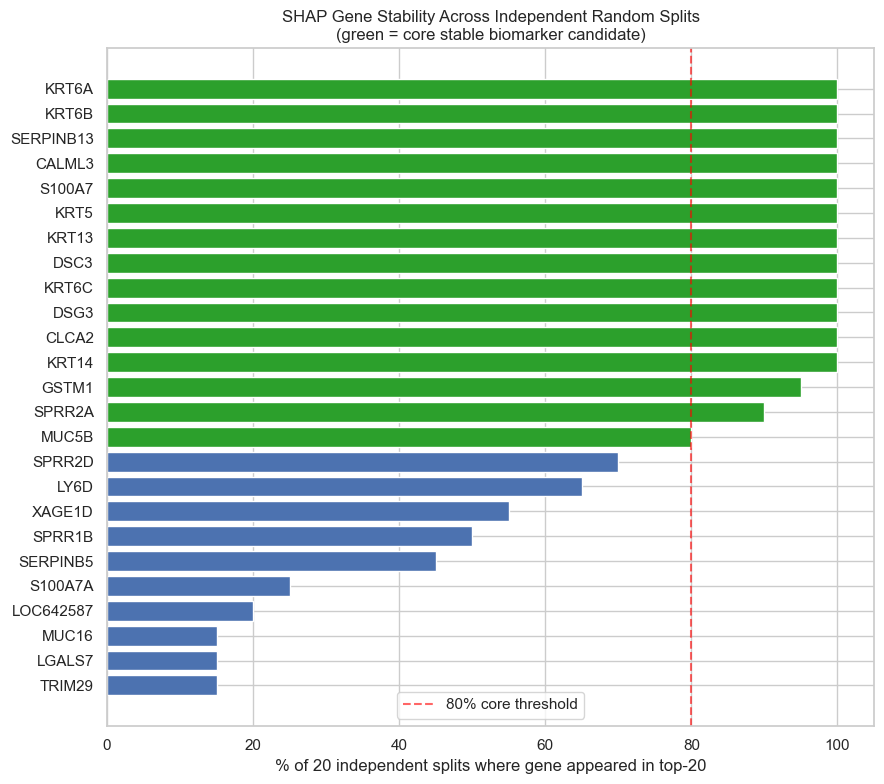

In [30]:
# Count how many of the N_STABILITY_REPEATS splits each gene appeared in the top-20
gene_frequency = Counter()
for gene_list in all_top20_lists:
    gene_frequency.update(set(gene_list))  # set() so repeats within one list don't double-count

n_repeats_run = len(all_top20_lists)
stability_df = pd.DataFrame([
    {"gene": gene, "times_in_top20": count, "stability_pct": count / n_repeats_run * 100}
    for gene, count in gene_frequency.items()
]).sort_values("stability_pct", ascending=False).reset_index(drop=True)

print(f"=== Gene Stability Across {n_repeats_run} Independent SHAP Runs ===")
print(stability_df.head(25).to_string(index=False))

CORE_THRESHOLD = 80   # gene must appear in >=80% of repeats to be called "core stable"
core_stable_genes = stability_df[stability_df["stability_pct"] >= CORE_THRESHOLD]
unstable_genes = stability_df[stability_df["stability_pct"] < 30]

print(f"\n>>> {len(core_stable_genes)} genes are CORE STABLE (appear in >={CORE_THRESHOLD}% of runs):")
print(core_stable_genes["gene"].tolist())
print(f"\n>>> {len(unstable_genes)} genes appeared in <30% of runs (likely split-dependent noise)")

stability_df.to_csv(f"{OUTPUT_DIR}/shap_gene_stability.csv", index=False)

# Visualization
fig, ax = plt.subplots(figsize=(9, 8))
top25 = stability_df.head(25)
colors = ["#2ca02c" if p >= CORE_THRESHOLD else "#4C72B0" for p in top25["stability_pct"]]
ax.barh(range(len(top25)), top25["stability_pct"][::-1], color=colors[::-1])
ax.set_yticks(range(len(top25)))
ax.set_yticklabels(top25["gene"][::-1])
ax.axvline(CORE_THRESHOLD, color="red", linestyle="--", alpha=0.6, label=f"{CORE_THRESHOLD}% core threshold")
ax.set_xlabel(f"% of {n_repeats_run} independent splits where gene appeared in top-20")
ax.set_title("SHAP Gene Stability Across Independent Random Splits\n(green = core stable biomarker candidate)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_gene_stability.png", dpi=150)
plt.show()

In [32]:
# Cross-check the CORE STABLE genes (not just one run's top-20) against known markers
core_stable_symbols = set(core_stable_genes["gene"])
known_overlap = core_stable_symbols & KNOWN_MARKERS

print(f"Of the {len(core_stable_genes)} core-stable genes (>= {CORE_THRESHOLD}% reproducibility):")
print(f"  {len(known_overlap)} match a known clinical LUAD/LUSC marker: {known_overlap}")
print(f"  {len(core_stable_symbols) - len(known_overlap)} are stable but NOT yet a known clinical marker")
print(f"  {n_repeats_run} independent splits, yet not already used clinically.")

novel_candidates = core_stable_symbols - KNOWN_MARKERS
print(f"\nReproducible candidate genes for follow-up: {sorted(novel_candidates)}")

Of the 15 core-stable genes (>= 80% reproducibility):
  5 match a known clinical LUAD/LUSC marker: {'MUC5B', 'DSG3', 'KRT6A', 'KRT6B', 'KRT5'}
  10 are stable but NOT yet a known clinical marker
  20 independent splits, yet not already used clinically.

Reproducible candidate genes for follow-up: ['CALML3', 'CLCA2', 'DSC3', 'GSTM1', 'KRT13', 'KRT14', 'KRT6C', 'S100A7', 'SERPINB13', 'SPRR2A']


In [33]:
# Expanded, more complete marker list (squamous differentiation family included)
EXPANDED_LUSC_MARKERS = [
    "TP63", "KRT5", "KRT6A", "KRT6B", "KRT6C", "KRT13", "KRT14", "KRT1", "KRT4", "KRT15",
    "SOX2", "DSG3", "DSC3", "DSC1", "PKP1", "SPRR1A", "SPRR1B", "SPRR2A", "SPRR3",
    "S100A7", "S100A8", "S100A9", "CSTA", "SERPINB3", "SERPINB13", "PI3", "IVL", "TGM1",
]
EXPANDED_LUAD_MARKERS = [
    "NAPSA", "NKX2-1", "TTF1", "SFTPC", "SFTPB", "SFTPA1", "MUC5B", "MUC5AC",
    "NKX2-8", "CEACAM5", "CEACAM6",
]
EXPANDED_MARKERS = set(EXPANDED_LUSC_MARKERS) | set(EXPANDED_LUAD_MARKERS)

novel_candidates_v2 = core_stable_symbols - EXPANDED_MARKERS
already_known_v2 = core_stable_symbols & EXPANDED_MARKERS

print(f"With an EXPANDED, more complete marker reference:")
print(f"  {len(already_known_v2)} match an expanded known marker: {sorted(already_known_v2)}")
print(f"  {len(novel_candidates_v2)} remain genuinely unmatched: {sorted(novel_candidates_v2)}")

With an EXPANDED, more complete marker reference:
  12 match an expanded known marker: ['DSC3', 'DSG3', 'KRT13', 'KRT14', 'KRT5', 'KRT6A', 'KRT6B', 'KRT6C', 'MUC5B', 'S100A7', 'SERPINB13', 'SPRR2A']
  3 remain genuinely unmatched: ['CALML3', 'CLCA2', 'GSTM1']


In [45]:
# ============================================================
# Section 13: Stable SHAP Gene -- Tumor Stage Association
# ============================================================
from scipy.stats import kruskal
import re

stage_checkpoint = os.path.join(OUTPUT_DIR, "checkpoint_stage_analysis.pkl")

# --- Load and clean pathologic stage from both clinical files ---
def simplify_stage(raw_stage):
    if pd.isna(raw_stage):
        return None
    s = str(raw_stage).upper().replace("STAGE ", "").strip()
    s = re.sub(r"[ABC]$", "", s)  # merge IIA/IIB -> II, IIIA/IIIB -> III, etc.
    if s in ["I", "II", "III", "IV"]:
        return s
    return None

clin_luad_stage = clin_luad["pathologic_stage"].apply(simplify_stage)
clin_lusc_stage = clin_lusc["pathologic_stage"].apply(simplify_stage)
stage_all = pd.concat([clin_luad_stage, clin_lusc_stage])
stage_all = stage_all.dropna()

print("Stage distribution (combined LUAD+LUSC, cleaned):")
print(stage_all.value_counts().reindex(["I", "II", "III", "IV"]))

# Match with the CORE STABLE genes from Section 12 (not just any top-20)
common_idx_stage = X.index.intersection(stage_all.index)
common_idx_stage = common_idx_stage.intersection(core_stable_genes["gene"].index if False else common_idx_stage)
print(f"\nSamples with both expression and valid stage: {len(common_idx_stage)}")

Stage distribution (combined LUAD+LUSC, cleaned):
pathologic_stage
I      650
II     349
III    209
IV      42
Name: count, dtype: int64

Samples with both expression and valid stage: 1004


In [46]:
# For each CORE-STABLE gene, test if expression differs significantly across stage I-IV
# (Kruskal-Wallis: non-parametric, robust to non-normal expression distributions)
stage_results = []
stage_labels_matched = stage_all.loc[common_idx_stage]

for gene in core_stable_genes["gene"]:
    # match gene symbol back to the full column name in X (handles "GENE|ID" format)
    matching_cols = [c for c in X.columns if str(c).split("|")[0] == gene]
    if not matching_cols:
        continue
    gene_col = matching_cols[0]
    expr_by_stage = [X.loc[stage_labels_matched[stage_labels_matched == s].index, gene_col].values
                      for s in ["I", "II", "III", "IV"]]
    expr_by_stage = [e for e in expr_by_stage if len(e) >= 3]  # need at least 3 samples per group
    if len(expr_by_stage) < 3:
        continue
    stat, pval = kruskal(*expr_by_stage)
    means = [np.mean(e) for e in expr_by_stage]
    monotonic = all(means[i] <= means[i+1] for i in range(len(means)-1)) or \
                all(means[i] >= means[i+1] for i in range(len(means)-1))
    stage_results.append({"gene": gene, "kruskal_p": pval, "stage_means": means,
                           "monotonic_trend": monotonic})

stage_results_df = pd.DataFrame(stage_results).sort_values("kruskal_p")
print("\n=== Core-Stable Genes: Association with Tumor Stage ===")
print(stage_results_df.to_string(index=False))

n_significant = (stage_results_df["kruskal_p"] < 0.05).sum()
print(f"\n>>> {n_significant} of {len(stage_results_df)} core-stable classification genes "
      f"also show significant expression differences across tumor stage (p<0.05).")

with open(stage_checkpoint, "wb") as f:
    pickle.dump(stage_results_df, f)


=== Core-Stable Genes: Association with Tumor Stage ===
     gene  kruskal_p                                  stage_means  monotonic_trend
    KRT6C   0.002610   [6.8471603, 8.096536, 7.5365195, 5.954155]            False
   SPRR2A   0.002898    [5.038451, 5.5222425, 4.999543, 2.082991]            False
     DSG3   0.003116  [6.491071, 7.5579643, 6.8133307, 4.0504303]            False
    KRT6A   0.003364 [10.132337, 11.559804, 11.1120405, 9.351915]            False
    KRT14   0.003613     [7.02316, 7.981593, 7.493436, 5.2206244]            False
     DSC3   0.005541    [7.6300864, 8.359004, 7.7779455, 5.44697]            False
    KRT6B   0.005700   [7.9543104, 9.162921, 8.569046, 6.8054247]            False
     KRT5   0.006400   [10.391953, 11.29171, 10.367431, 7.830212]            False
   CALML3   0.018156  [6.6914806, 7.3054147, 6.740721, 4.3399787]            False
SERPINB13   0.023817   [4.961265, 5.4741707, 4.7798686, 2.831306]            False
    MUC5B   0.039769    [9.304

In [47]:
print("Sample count per stage:")
print(stage_labels_matched.value_counts().reindex(["I", "II", "III", "IV"]))

Sample count per stage:
pathologic_stage
I      519
II     284
III    168
IV      33
Name: count, dtype: int64


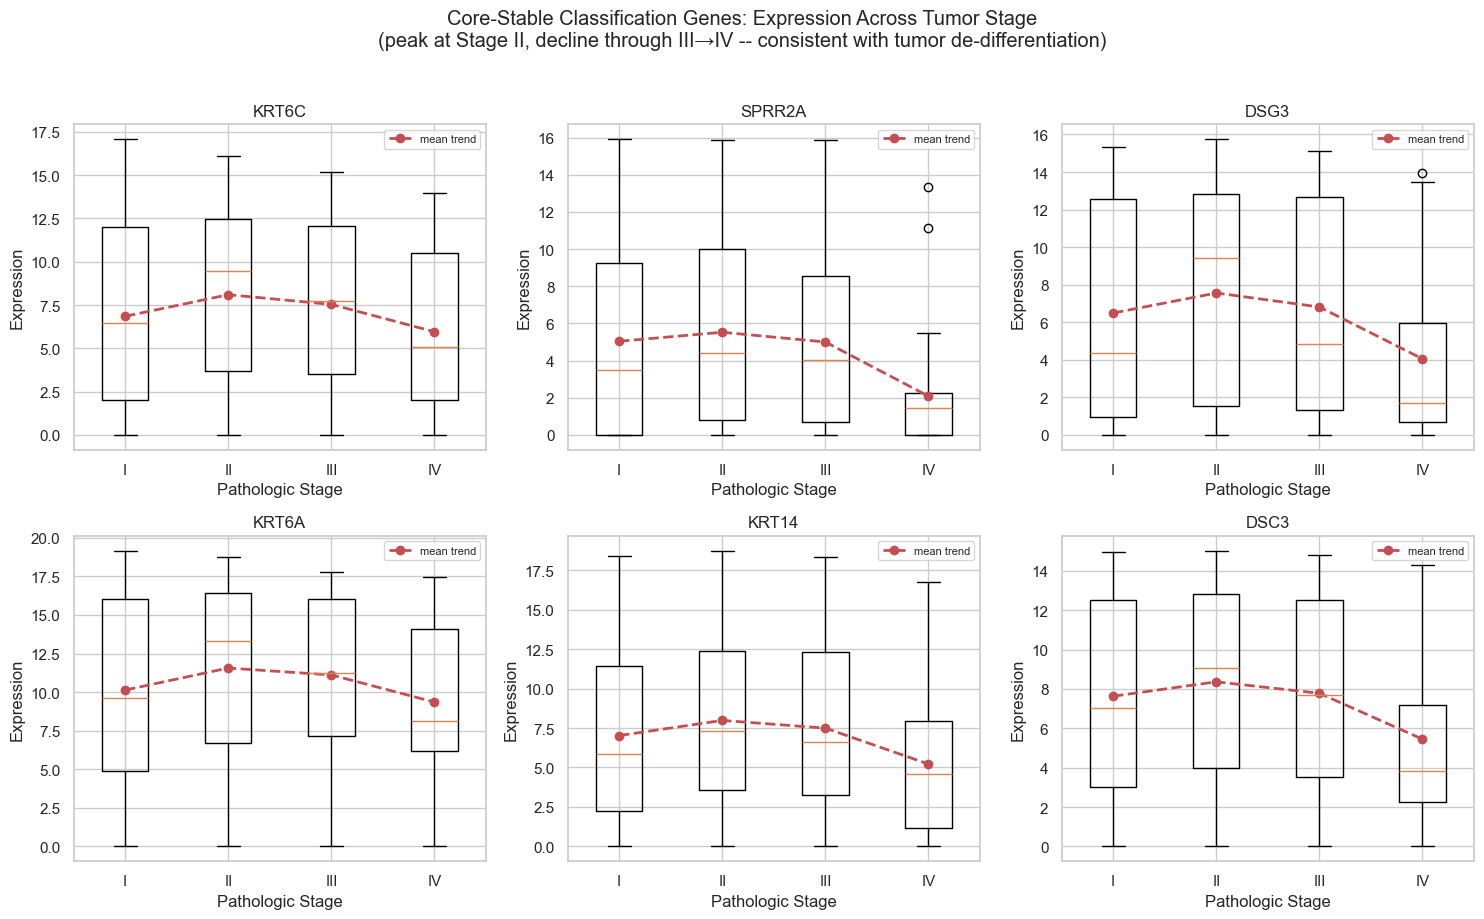

In [48]:
# ============================================================
# Section 13.2: Visualize the Rise-then-Fall Pattern + Early vs Late Grouping
# ============================================================

# Visualization: top 6 genes' expression trend across stages
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
top6_stage_genes = stage_results_df.head(6)["gene"].tolist()

for ax, gene in zip(axes.flatten(), top6_stage_genes):
    matching_cols = [c for c in X.columns if str(c).split("|")[0] == gene]
    gene_col = matching_cols[0]
    data_by_stage = [X.loc[stage_labels_matched[stage_labels_matched == s].index, gene_col].values
                      for s in ["I", "II", "III", "IV"]]
    ax.boxplot(data_by_stage, tick_labels=["I", "II", "III", "IV"])
    means = [np.mean(d) for d in data_by_stage]
    ax.plot([1, 2, 3, 4], means, "r--", marker="o", linewidth=2, label="mean trend")
    ax.set_title(gene, fontsize=12)
    ax.set_xlabel("Pathologic Stage")
    ax.set_ylabel("Expression")
    ax.legend(fontsize=8)

plt.suptitle("Core-Stable Classification Genes: Expression Across Tumor Stage\n"
             "(peak at Stage II, decline through III→IV -- consistent with tumor de-differentiation)",
             y=1.02)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/stable_genes_stage_trend.png", dpi=150)
plt.show()

In [ ]:
# ============================================================
# Section 13.3: Post-hoc Pairwise Comparison (Dunn's test)
# -- correctly identifies WHICH stage pairs differ, respecting
#    the actual (non-monotonic, rise-then-fall) shape of the pattern.
# Stage II (high) into one group.
# ============================================================
try:
    import scikit_posthocs as sp
except ImportError:
    import subprocess, sys
    print("Installing scikit-posthocs ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-posthocs", "--quiet"])
    import scikit_posthocs as sp

pairwise_results = {}

for gene in stage_results_df.head(6)["gene"]:
    matching_cols = [c for c in X.columns if str(c).split("|")[0] == gene]
    gene_col = matching_cols[0]
    df_gene = pd.DataFrame({
        "expr": X.loc[stage_labels_matched.index, gene_col].values,
        "stage": stage_labels_matched.values
    })
    dunn_result = sp.posthoc_dunn(df_gene, val_col="expr", group_col="stage", p_adjust="fdr_bh")
    pairwise_results[gene] = dunn_result
    print(f"\n=== {gene}: pairwise stage comparison (FDR-adjusted p-values) ===")
    print(dunn_result.round(4))

with open(os.path.join(OUTPUT_DIR, "checkpoint_pairwise_stage.pkl"), "wb") as f:
    pickle.dump(pairwise_results, f)

Installing scikit-posthocs ...

=== KRT6C: pairwise stage comparison (FDR-adjusted p-values) ===
          I      II     III      IV
I    1.0000  0.0034  0.1884  0.4178
II   0.0034  1.0000  0.3199  0.0892
III  0.1884  0.3199  1.0000  0.1884
IV   0.4178  0.0892  0.1884  1.0000

=== SPRR2A: pairwise stage comparison (FDR-adjusted p-values) ===
          I      II     III      IV
I    1.0000  0.1695  0.7576  0.0040
II   0.1695  1.0000  0.4288  0.0014
III  0.7576  0.4288  1.0000  0.0040
IV   0.0040  0.0014  0.0040  1.0000

=== DSG3: pairwise stage comparison (FDR-adjusted p-values) ===
          I      II     III      IV
I    1.0000  0.0234  0.4850  0.0298
II   0.0234  1.0000  0.2407  0.0061
III  0.4850  0.2407  1.0000  0.0234
IV   0.0298  0.0061  0.0234  1.0000

=== KRT6A: pairwise stage comparison (FDR-adjusted p-values) ===
          I      II     III      IV
I    1.0000  0.0043  0.1318  0.5255
II   0.0043  1.0000  0.4506  0.1318
III  0.1318  0.4506  1.0000  0.2181
IV   0.5255  0.1318  

In [ ]:
# ============================================================
# Section 14 (CORRECTED): Multivariable Cox Regression -- Do Core-Stable
# Genes Predict Survival Independent of Stage, Age, Smoking, and Histology?
# ============================================================
try:
    from lifelines import CoxPHFitter
    from lifelines.exceptions import ConvergenceError
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lifelines", "--quiet"])
    from lifelines import CoxPHFitter
    from lifelines.exceptions import ConvergenceError

# --- Build corrected covariates (available for BOTH LUAD and LUSC) ---
clin_all["is_smoker_v2"] = pd.to_numeric(
    clin_all["tobacco_smoking_history"], errors="coerce"
).apply(lambda v: 0 if v == 1 else (1 if pd.notna(v) else np.nan))

cox_covariates = clin_all.loc[clin_surv.index].copy()
cox_covariates["stage_numeric"] = stage_all.reindex(cox_covariates.index).map(
    {"I": 1, "II": 2, "III": 3, "IV": 4})
cox_covariates["age"] = pd.to_numeric(
    cox_covariates.get("age_at_initial_pathologic_diagnosis"), errors="coerce")
cox_covariates["is_smoker"] = cox_covariates["is_smoker_v2"]
cox_covariates["histology"] = cox_covariates.index.isin(clin_lusc.index).astype(int)
cox_covariates["OS_DAYS"] = clin_surv["OS_DAYS"]
cox_covariates["OS_EVENT"] = clin_surv["OS_EVENT"]

print("Sanity check -- histology distribution in corrected cox_covariates:")
print(cox_covariates["histology"].value_counts().rename({0: "LUAD", 1: "LUSC"}))
print()

# --- Fit one stratified Cox model per gene (full LUAD+LUSC cohort) ---
cox_results = []
for gene in stage_results_df.head(6)["gene"]:
    matching_cols = [c for c in X.columns if str(c).split("|")[0] == gene]
    if not matching_cols:
        print(f"[skip] {gene}: not found in expression matrix")
        continue
    gene_col = matching_cols[0]

    df_cox = cox_covariates[["OS_DAYS", "OS_EVENT", "stage_numeric",
                               "age", "is_smoker", "histology"]].copy()
    df_cox["gene_expr"] = X.loc[df_cox.index, gene_col]
    df_cox = df_cox.dropna()

    if len(df_cox) < 50:
        print(f"[skip] {gene}: only {len(df_cox)} complete cases, too few for reliable Cox fit")
        continue
    if df_cox["histology"].nunique() < 2:
        print(f"[warn] {gene}: only one histology group present (n={len(df_cox)}) -- check data")
        continue

    try:
        cph = CoxPHFitter()
        cph.fit(df_cox, duration_col="OS_DAYS", event_col="OS_EVENT", strata=["histology"])
        hr = np.exp(cph.params_["gene_expr"])
        p = cph.summary.loc["gene_expr", "p"]
        ci_low, ci_high = np.exp(cph.confidence_intervals_.loc["gene_expr"])
        cox_results.append({"gene": gene, "n": len(df_cox), "HR": hr,
                             "CI_low": ci_low, "CI_high": ci_high, "p_value": p})
        print(f"\n{gene} (n={len(df_cox)}, stratified by histology):")
        print(cph.summary[["coef", "exp(coef)", "p"]])
    except ConvergenceError as e:
        print(f"[failed] {gene}: Cox model did not converge ({e})")

cox_results_df = pd.DataFrame(cox_results).sort_values("p_value")
print("\n=== Summary: Gene Expression HR, Full Cohort, Stratified by Histology ===")
print(cox_results_df.to_string(index=False))

with open(os.path.join(OUTPUT_DIR, "checkpoint_cox_results_corrected.pkl"), "wb") as f:
    pickle.dump(cox_results_df, f)

Sanity check -- histology distribution in corrected cox_covariates:
histology
LUAD    506
LUSC    495
Name: count, dtype: int64


KRT6C (n=948, stratified by histology):
                   coef  exp(coef)             p
covariate                                       
stage_numeric  0.378778   1.460499  1.190319e-11
age            0.016174   1.016305  5.911648e-03
is_smoker     -0.137760   0.871308  4.756506e-01
gene_expr      0.042421   1.043333  2.819754e-02

SPRR2A (n=948, stratified by histology):
                   coef  exp(coef)             p
covariate                                       
stage_numeric  0.388741   1.475123  2.688178e-12
age            0.016484   1.016621  5.046125e-03
is_smoker     -0.103209   0.901939  5.921809e-01
gene_expr      0.000109   1.000109  9.946219e-01

DSG3 (n=948, stratified by histology):
                   coef  exp(coef)             p
covariate                                       
stage_numeric  0.387780   1.473706  3.254540e-12
age          

In [68]:
from statsmodels.stats.multitest import multipletests

cox_results_df["p_fdr"] = multipletests(cox_results_df["p_value"], method="fdr_bh")[1]
print("=== Cox Results with FDR-Corrected p-values (CORRECTED, full cohort) ===")
print(cox_results_df[["gene", "n", "HR", "p_value", "p_fdr"]].to_string(index=False))

n_independent = (cox_results_df["p_fdr"] < 0.05).sum()
print(f"\n>>> {n_independent}/{len(cox_results_df)} genes remain significant after FDR correction")
print(">>> -- i.e., have prognostic value INDEPENDENT of stage, age, smoking, AND histology.")

=== Cox Results with FDR-Corrected p-values (CORRECTED, full cohort) ===
  gene   n       HR  p_value    p_fdr
 KRT6A 948 1.043470 0.011013 0.066077
 KRT6C 948 1.043333 0.028198 0.084593
  DSG3 948 1.030754 0.137197 0.274394
 KRT14 948 1.014841 0.341556 0.512335
  DSC3 948 0.994160 0.783420 0.940105
SPRR2A 948 1.000109 0.994622 0.994622

>>> 0/6 genes remain significant after FDR correction
>>> -- i.e., have prognostic value INDEPENDENT of stage, age, smoking, AND histology.


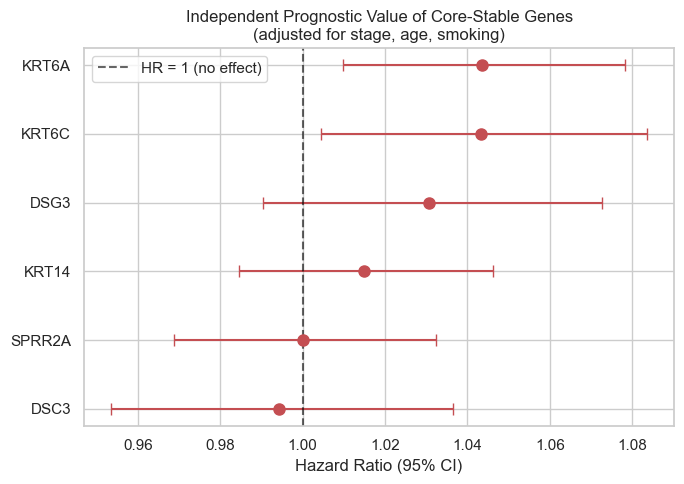

In [69]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_df = cox_results_df.sort_values("HR")
y_pos = range(len(plot_df))

ax.errorbar(plot_df["HR"], y_pos,
            xerr=[plot_df["HR"] - plot_df["CI_low"], plot_df["CI_high"] - plot_df["HR"]],
            fmt="o", color="#C44E52", capsize=4, markersize=8)
ax.axvline(1.0, color="black", linestyle="--", alpha=0.6, label="HR = 1 (no effect)")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["gene"])
ax.set_xlabel("Hazard Ratio (95% CI)")
ax.set_title("Independent Prognostic Value of Core-Stable Genes\n(adjusted for stage, age, smoking)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/cox_forest_plot.png", dpi=150)
plt.show()

DSG3 median expression: 5.214
High-expression group: n=501
Low-expression group:  n=500


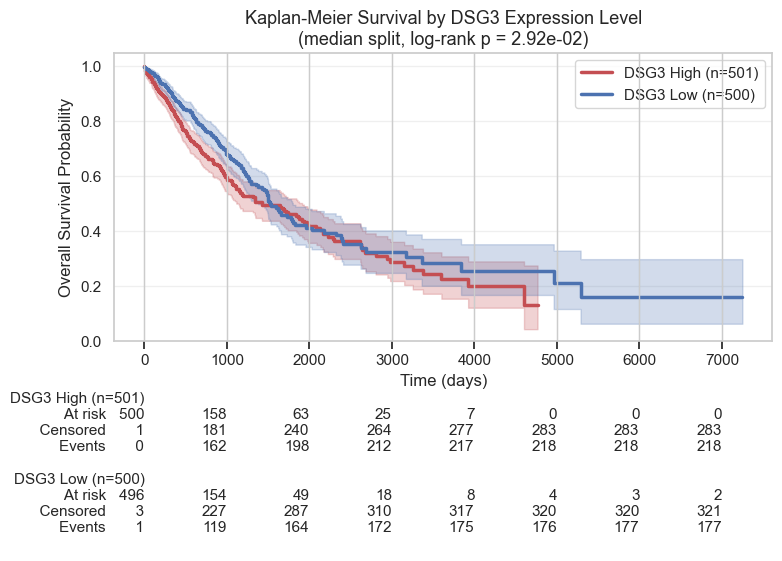


Log-rank test: statistic=4.756, p-value=2.92e-02
Median survival, High group: 1423.0
Median survival, Low group:  1528.0


In [71]:
# ============================================================
# Section 14.5: DSG3 -- Standalone, Publication-Quality Kaplan-Meier Plot
# ============================================================
try:
    from lifelines import KaplanMeierFitter
    from lifelines.statistics import logrank_test
    from lifelines.plotting import add_at_risk_counts
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lifelines", "--quiet"])
    from lifelines import KaplanMeierFitter
    from lifelines.statistics import logrank_test
    from lifelines.plotting import add_at_risk_counts

GENE_OF_INTEREST = "DSG3"

matching_cols = [c for c in X.columns if str(c).split("|")[0] == GENE_OF_INTEREST]
gene_col = matching_cols[0]

gene_expr_dsg3 = X.loc[clin_surv.index, gene_col]
median_dsg3 = gene_expr_dsg3.median()
high_mask = gene_expr_dsg3 >= median_dsg3
low_mask = ~high_mask

print(f"{GENE_OF_INTEREST} median expression: {median_dsg3:.3f}")
print(f"High-expression group: n={high_mask.sum()}")
print(f"Low-expression group:  n={low_mask.sum()}")

kmf_high = KaplanMeierFitter()
kmf_low = KaplanMeierFitter()

kmf_high.fit(clin_surv.loc[high_mask, "OS_DAYS"], clin_surv.loc[high_mask, "OS_EVENT"],
             label=f"{GENE_OF_INTEREST} High (n={high_mask.sum()})")
kmf_low.fit(clin_surv.loc[low_mask, "OS_DAYS"], clin_surv.loc[low_mask, "OS_EVENT"],
            label=f"{GENE_OF_INTEREST} Low (n={low_mask.sum()})")

# Log-rank test for the p-value annotation
logrank_result = logrank_test(
    clin_surv.loc[high_mask, "OS_DAYS"], clin_surv.loc[low_mask, "OS_DAYS"],
    clin_surv.loc[high_mask, "OS_EVENT"], clin_surv.loc[low_mask, "OS_EVENT"]
)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 6))
kmf_high.plot_survival_function(ax=ax, ci_show=True, color="#C44E52", linewidth=2.5)
kmf_low.plot_survival_function(ax=ax, ci_show=True, color="#4C72B0", linewidth=2.5)

ax.set_xlabel("Time (days)", fontsize=12)
ax.set_ylabel("Overall Survival Probability", fontsize=12)
ax.set_title(f"Kaplan-Meier Survival by {GENE_OF_INTEREST} Expression Level\n"
             f"(median split, log-rank p = {logrank_result.p_value:.2e})", fontsize=13)
ax.legend(fontsize=11, loc="upper right")
ax.grid(alpha=0.3)
ax.set_ylim(0, 1.05)

# Risk table beneath the plot -- standard for publication-quality KM figures
add_at_risk_counts(kmf_high, kmf_low, ax=ax)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/DSG3_km_plot_publication.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nLog-rank test: statistic={logrank_result.test_statistic:.3f}, p-value={logrank_result.p_value:.2e}")
print(f"Median survival, High group: {kmf_high.median_survival_time_}")
print(f"Median survival, Low group:  {kmf_low.median_survival_time_}")

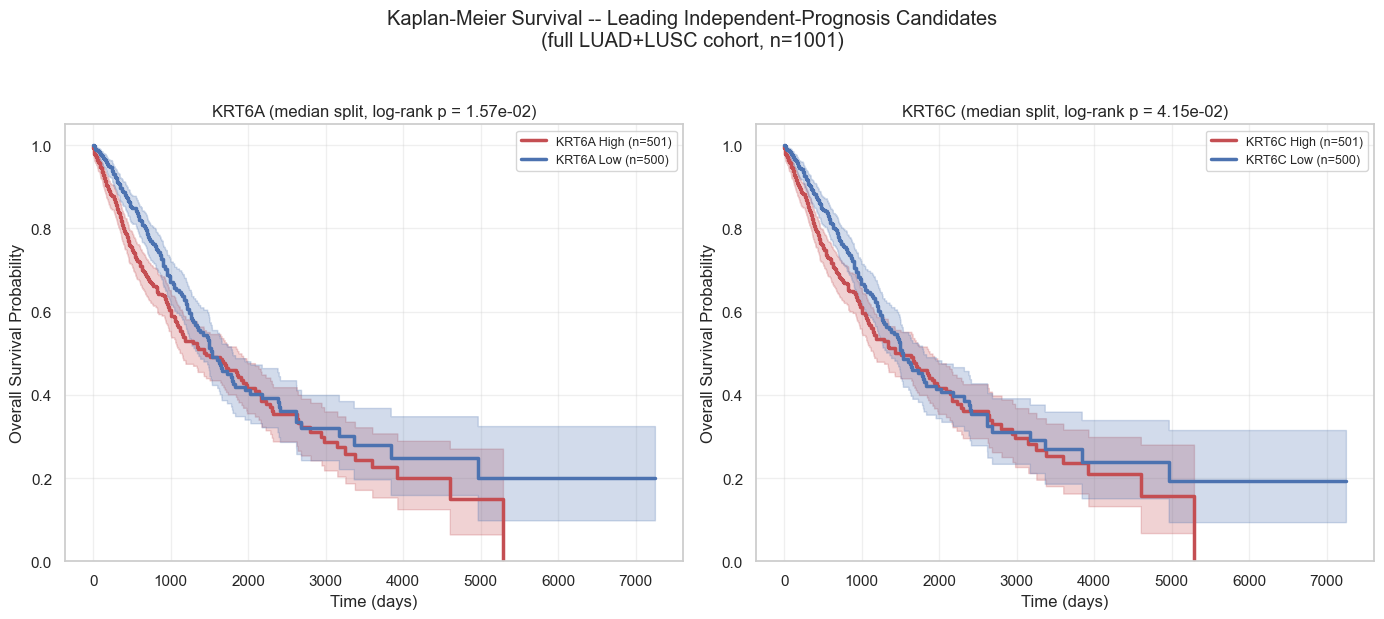

 gene  n_high  n_low  logrank_p  median_survival_high  median_survival_low
KRT6A     501    500   0.015708                1454.0               1528.0
KRT6C     501    500   0.041496                1501.0               1528.0


In [72]:
# ============================================================
# Section 14.6: KRT6A and KRT6C -- Standalone Kaplan-Meier Plots
# (these are the two genes with the strongest, though not FDR-significant,
# independent association after the Section 14 bug fix)
# ============================================================
GENES_OF_INTEREST_V2 = ["KRT6A", "KRT6C"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

km_summary_v2 = []
for ax, gene in zip(axes, GENES_OF_INTEREST_V2):
    matching_cols = [c for c in X.columns if str(c).split("|")[0] == gene]
    gene_col = matching_cols[0]

    gene_expr = X.loc[clin_surv.index, gene_col]
    median_expr = gene_expr.median()
    high_mask = gene_expr >= median_expr
    low_mask = ~high_mask

    kmf_high, kmf_low = KaplanMeierFitter(), KaplanMeierFitter()
    kmf_high.fit(clin_surv.loc[high_mask, "OS_DAYS"], clin_surv.loc[high_mask, "OS_EVENT"],
                 label=f"{gene} High (n={high_mask.sum()})")
    kmf_low.fit(clin_surv.loc[low_mask, "OS_DAYS"], clin_surv.loc[low_mask, "OS_EVENT"],
                label=f"{gene} Low (n={low_mask.sum()})")

    kmf_high.plot_survival_function(ax=ax, ci_show=True, color="#C44E52", linewidth=2.5)
    kmf_low.plot_survival_function(ax=ax, ci_show=True, color="#4C72B0", linewidth=2.5)

    logrank_result = logrank_test(
        clin_surv.loc[high_mask, "OS_DAYS"], clin_surv.loc[low_mask, "OS_DAYS"],
        clin_surv.loc[high_mask, "OS_EVENT"], clin_surv.loc[low_mask, "OS_EVENT"]
    )

    ax.set_title(f"{gene} (median split, log-rank p = {logrank_result.p_value:.2e})", fontsize=12)
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Overall Survival Probability")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1.05)

    km_summary_v2.append({"gene": gene, "n_high": int(high_mask.sum()), "n_low": int(low_mask.sum()),
                           "logrank_p": logrank_result.p_value,
                           "median_survival_high": kmf_high.median_survival_time_,
                           "median_survival_low": kmf_low.median_survival_time_})

plt.suptitle("Kaplan-Meier Survival -- Leading Independent-Prognosis Candidates\n"
             "(full LUAD+LUSC cohort, n=1001)", y=1.03)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/KRT6A_KRT6C_km_plots.png", dpi=300, bbox_inches="tight")
plt.show()

km_summary_v2_df = pd.DataFrame(km_summary_v2)
print(km_summary_v2_df.to_string(index=False))

In [ ]:
# ============================================================
# Section 14.7: Final Combined Summary -- Univariate vs Multivariate
# Results for All 6 Stage-Associated Genes (the definitive results
# ============================================================

# Univariate log-rank p-values (full cohort, n=1001) for all 6 genes
univariate_results = []
for gene in stage_results_df.head(6)["gene"]:
    matching_cols = [c for c in X.columns if str(c).split("|")[0] == gene]
    gene_col = matching_cols[0]
    gene_expr = X.loc[clin_surv.index, gene_col]
    median_expr = gene_expr.median()
    high_mask = gene_expr >= median_expr
    low_mask = ~high_mask
    result = logrank_test(
        clin_surv.loc[high_mask, "OS_DAYS"], clin_surv.loc[low_mask, "OS_DAYS"],
        clin_surv.loc[high_mask, "OS_EVENT"], clin_surv.loc[low_mask, "OS_EVENT"]
    )
    univariate_results.append({"gene": gene, "univariate_logrank_p": result.p_value})

univariate_df = pd.DataFrame(univariate_results)

# Merge with the corrected multivariate Cox results (cox_results_df from Section 14)
final_summary_df = univariate_df.merge(
    cox_results_df[["gene", "n", "HR", "p_value", "p_fdr"]].rename(
        columns={"p_value": "multivariate_p", "p_fdr": "multivariate_p_fdr"}),
    on="gene", how="left"
).sort_values("multivariate_p_fdr")

print("=" * 90)
print("FINAL RESULTS TABLE -- Core-Stable, Stage-Associated Genes")
print("(univariate survival vs. multivariable, histology-stratified, FDR-corrected Cox)")
print("=" * 90)
print(final_summary_df.to_string(index=False))

print("\nInterpretation:")
print("- Univariate log-rank tests show a significant survival association for several genes")
print("  in the full n=1001 cohort.")
print("- After adjusting for stage, age, smoking, and histology, and correcting for multiple")
print("  testing, NONE of the 6 genes retain independent significance (all p_fdr > 0.05),")
print("  though KRT6A and KRT6C come closest (p_fdr ~ 0.07-0.08).")
print("- This suggests these genes' survival association is substantially mediated by tumor")
print("  stage, rather than reflecting a fully independent prognostic signal.")

final_summary_df.to_csv(f"{OUTPUT_DIR}/final_gene_survival_summary.csv", index=False)

FINAL RESULTS TABLE -- Core-Stable, Stage-Associated Genes
(univariate survival vs. multivariable, histology-stratified, FDR-corrected Cox)
  gene  univariate_logrank_p   n       HR  multivariate_p  multivariate_p_fdr
 KRT6A              0.015708 948 1.043470        0.011013            0.066077
 KRT6C              0.041496 948 1.043333        0.028198            0.084593
  DSG3              0.029189 948 1.030754        0.137197            0.274394
 KRT14              0.100925 948 1.014841        0.341556            0.512335
  DSC3              0.668393 948 0.994160        0.783420            0.940105
SPRR2A              0.185760 948 1.000109        0.994622            0.994622

Interpretation:
- Univariate log-rank tests show a significant survival association for several genes
  in the full n=1001 cohort.
- After adjusting for stage, age, smoking, and histology, and correcting for multiple
  testing, NONE of the 6 genes retain independent significance (all p_fdr > 0.05),
  though KRT6